# AI Workforce Intelligence: Phases 1 and 2 (CS3216 Time Series Analysis and Forecasting)

**Phase 1** explores seven demand and cost series and sets simple benchmark forecasts.
**Phase 2** fits smoothing, ARIMA, machine-learning and ensemble models and compares them all
with the same rolling-origin backtest. Every number below is read from the project's own output files.

> **How to use this notebook**
> 1. In Colab: *Runtime > Run all*. When asked, upload `ai-workforce-intel_colab.zip`.
> 2. `MODE = "show"` (default) only displays the finished results inside the zip: under 1 minute.
> 3. `MODE = "run"` recomputes Phase 1 and Phase 2 first (fast mode about 5 to 10 minutes on Colab).
> 4. Outside Colab, put the unzipped `ai-workforce-intel` folder (or the zip) next to this notebook.

In [1]:
# ---- Settings: change these, then Runtime > Run all ----
MODE = "show"       # "show": display the finished results in the bundle (under 1 minute)
                    # "run":  recompute Phase 1 and Phase 2 first, then display the new results
RUN_FAST = True     # only for MODE = "run": True = --fast (3 folds, smaller grids), False = full run
WITH_LSTM = False   # only for MODE = "run": also train the optional LSTM challenger (needs torch)
DRIVERS = None      # None = all drivers, or a list such as ["burst_tokens_total_daily"]

import os
MODE = os.environ.get("TSAF_MODE", MODE)  # used only by the automated test; ignore in Colab
print("MODE =", MODE, "| RUN_FAST =", RUN_FAST, "| WITH_LSTM =", WITH_LSTM, "| DRIVERS =", DRIVERS or "all")

MODE = show | RUN_FAST = True | WITH_LSTM = False | DRIVERS = all


### Helper functions
Small helpers used by every step: `step` turns any problem into a one-line message (so *Run all*
never stops), `show_img` and `show_table` display figures and tables at a readable size.

In [2]:
import contextlib, json, re, subprocess, sys, time, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)

@contextlib.contextmanager
def step(name):
    """Run one notebook step; a problem prints a short message instead of a traceback."""
    try:
        yield
    except FileNotFoundError as exc:
        print(f"[{name}] skipped: a result file is missing ({Path(str(exc.filename or exc)).name}).")
    except Exception as exc:
        print(f"[{name}] skipped: {type(exc).__name__}: {str(exc)[:200]}")

def show_img(path, width=900):
    """Display a saved PNG figure, or a short message if it does not exist."""
    path = Path(path)
    if not path.exists():
        print(f"No figure {path.name}; skipped.")
        return
    display(Image(filename=str(path), width=width))

def show_table(df, n=10, cols=None, digits=3):
    """Display the first n rows of a table, selected columns, rounded numbers."""
    if df is None or len(df) == 0:
        print("No rows to show.")
        return
    df = df[[c for c in cols if c in df.columns]] if cols else df
    display(df.head(n).round(digits).reset_index(drop=True))

def read_table(phase, name):
    """Read outputs/<phase>/tables/<name>.csv."""
    return pd.read_csv(Path("outputs") / phase / "tables" / f"{name}.csv")

def md_section(path, title):
    """Text of the '## ... title ...' section of a generated summary file (None if absent)."""
    text = Path(path).read_text(encoding="utf-8")
    pat = r"^## [^\n]*" + re.escape(title) + r"[^\n]*\n(.*?)(?=^## |\Z)"
    m = re.search(pat, text, flags=re.M | re.S)
    return m.group(1).strip() if m else None

## Setup 1: get the project
If the project folder is not here yet, the cell asks you to upload `ai-workforce-intel_colab.zip`
(about 8 MB), unzips it and moves into the folder. Outside Colab it looks for the folder (or the zip)
next to the notebook. The commented lines show how to unzip it from Google Drive instead.

In [3]:
def _is_project(p):
    return (p / "src" / "run_phase2.py").exists()

def _find_project():
    here = Path.cwd()
    for c in (here, here / "ai-workforce-intel", Path("/content/ai-workforce-intel")):
        if _is_project(c):
            return c
    return None

def _get_zip():
    if os.environ.get("TSAF_BUNDLE_PATH"):          # automated test: no upload dialog
        return Path(os.environ["TSAF_BUNDLE_PATH"])
    if Path("ai-workforce-intel_colab.zip").exists():
        return Path("ai-workforce-intel_colab.zip")
    try:
        from google.colab import files               # only exists inside Colab
    except ImportError:
        print("Not in Colab: place ai-workforce-intel_colab.zip or the unzipped folder next to this notebook.")
        return None
    print("Please upload ai-workforce-intel_colab.zip")
    uploaded = files.upload()
    return Path(next(iter(uploaded))) if uploaded else None

# Alternative: unzip from Google Drive instead of uploading (uncomment the two lines):
# from google.colab import drive; drive.mount("/content/drive")
# import zipfile; zipfile.ZipFile("/content/drive/MyDrive/ai-workforce-intel_colab.zip").extractall("/content")

PROJECT = None
with step("get the project"):
    PROJECT = _find_project()
    if PROJECT is None:
        zpath = _get_zip()
        if zpath is not None and zpath.exists():
            import zipfile
            base = Path("/content") if Path("/content").is_dir() else Path.cwd()
            zipfile.ZipFile(zpath).extractall(base)
            PROJECT = base / "ai-workforce-intel"
    if PROJECT is not None and _is_project(PROJECT):
        os.chdir(PROJECT)
        if str(PROJECT / "src") not in sys.path:
            sys.path.insert(0, str(PROJECT / "src"))
        print("Project ready: working folder is", Path.cwd().name)
    else:
        print("Project not found. Upload the zip and run this cell again.")

Project ready: working folder is ai-workforce-intel


## Setup 2: packages
Colab already has pandas, numpy, statsmodels, scikit-learn, matplotlib and pyarrow. This cell installs
only what is missing from `requirements.txt`, plus `xgboost` if it is missing. Prophet and torch are
optional and are never installed automatically; the project skips those models when they are absent.

In [4]:
IMPORT_NAME = {"scikit-learn": "sklearn"}
with step("packages"):
    import importlib
    wanted = []
    for line in Path("requirements.txt").read_text().splitlines():
        line = line.split("#")[0].strip()
        if line:
            wanted.append(re.split(r"[<>=!~ ]", line)[0])
    missing = []
    for pkg in wanted + ["xgboost"]:
        try:
            importlib.import_module(IMPORT_NAME.get(pkg, pkg))
        except ImportError:
            missing.append(pkg)
    if missing:
        print("Installing:", ", ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=False)
    else:
        print("All required packages are already installed.")
    import numpy, statsmodels, sklearn, matplotlib
    print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {numpy.__version__} | "
          f"statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
    import optional
    for name, ok in [("xgboost", optional.has_xgboost()), ("prophet", optional.has_prophet()), ("torch (LSTM)", optional.has_torch())]:
        print(f"  optional {name:13s}: {'available' if ok else 'not installed (model skipped)'}")

All required packages are already installed.
Python 3.11.9 | pandas 3.0.5 | numpy 2.4.6 | statsmodels 0.15.0 | scikit-learn 1.9.0 | matplotlib 3.11.1


  optional xgboost      : available
  optional prophet      : not installed (model skipped)
  optional torch (LSTM) : available


## Setup 3: seeds and project layout
All randomness (random forest, XGBoost, LSTM) uses seed 42, so a rerun gives the same numbers.

In [5]:
with step("seeds and tree"):
    import random, numpy as np
    random.seed(42)
    np.random.seed(42)
    for top in sorted(p for p in Path(".").iterdir() if p.is_dir() and not p.name.startswith(".")):
        subs = sorted(q.name for q in top.iterdir() if q.is_dir() and q.name != "__pycache__")
        print(f"{top.name}/" + (f"  ->  {', '.join(subs)}" if subs else ""))

data/  ->  processed
outputs/  ->  phase1, phase2
reports/  ->  figures
src/  ->  tsaf
tests/


## Run (only when `MODE = "run"`)
In `show` mode nothing is recomputed. In `run` mode this cell runs the two project scripts exactly
as you would in a terminal: `python src/run_phase1.py` and `python src/run_phase2.py`, then the rest
of the notebook displays the new results.

In [6]:
def run_script(args):
    """Run one project script and print the last lines of its log."""
    t0 = time.time()
    res = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    for line in (res.stdout + res.stderr).strip().splitlines()[-8:]:
        print("   ", line[:150])
    print(f"  -> exit code {res.returncode}, {time.time() - t0:.0f} s")
    return res.returncode

with step("run"):
    if MODE == "run":
        extra = ["--drivers", *DRIVERS] if DRIVERS else []
        fast = ["--fast"] if RUN_FAST else []
        print("Estimated time on Colab's CPU: Phase 1 about 1 to 5 minutes; Phase 2 about 4 minutes with "
              "--fast, 20 minutes or more for the full run.")
        T0 = time.time()
        print("Phase 1 ...")
        if run_script(["src/run_phase1.py", *fast, *extra]) == 0:
            print("Phase 2 ...")
            run_script(["src/run_phase2.py", *fast, *(["--with-lstm"] if WITH_LSTM else []), *extra])
        print(f"Total elapsed: {(time.time() - T0) / 60:.1f} minutes")
    else:
        print("MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).")

MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).


# Part A: the data

The project models **seven drivers** (time series). The table comes from `outputs/phase1/handoff.json`,
the file Phase 1 writes for Phase 2: grain (daily, hourly, monthly, quarterly), number of observations,
the index or date range, and the seasonal period (7 = weekly cycle in daily data, 24 = daily cycle in
hourly data, 12 = yearly cycle in monthly data, 4 = yearly cycle in quarterly data).

In [7]:
NAMES = []
with step("drivers"):
    HANDOFF = json.loads(Path("outputs/phase1/handoff.json").read_text(encoding="utf-8"))
    NAMES = [d["name"] for d in HANDOFF["drivers"] if not DRIVERS or d["name"] in DRIVERS]
    stats = read_table("phase1", "summary_stats").set_index("driver")
    rows = [{"driver": d["name"], "grain": d["grain"], "n": d["n_obs"],
             "from": stats.loc[d["name"], "start"] if d["name"] in stats.index else "",
             "to": stats.loc[d["name"], "end"] if d["name"] in stats.index else "",
             "season": d["season"], "extra seasons": ", ".join(map(str, d["extra_seasons"])) or "-"}
            for d in HANDOFF["drivers"] if d["name"] in NAMES]
    show_table(pd.DataFrame(rows), n=20)
    print("Not analysed:", "; ".join(f"{s['name']} ({s['reason'][:70]})" for s in HANDOFF.get("skipped", [])))

,driver,grain,n,from,to,season,extra seasons
0,burst_tokens_total_daily,daily,87,0,86,7,-
1,burst_tokens_api_daily,daily,87,0,86,7,-
2,burst_tokens_chat_daily,daily,87,0,86,7,-
3,burst_requests_hourly,hourly,2088,0,2087,24,168
4,wildchat_conversations_daily,daily,121,2024-03-04,2024-07-02,7,-
5,eci_wages_quarterly,quarterly,103,2001-01-01,2026-07-01,4,-
6,ppi_hosting_monthly,monthly,311,2000-12-01,2026-10-01,12,-


Not analysed: wildchat_conversations_weekly (2 missing or partial value(s) inside the series (2023-10-09, 2024-01-1); wildchat_new_users_weekly (2 missing or partial value(s) inside the series (2023-10-09, 2024-01-1); wildchat_returning_share_weekly (2 missing or partial value(s) inside the series (2023-10-09, 2024-01-1); epoch_cheapest_price_monthly (file 'epoch_prices_monthly' not found in data/processed)


**The BurstGPT modelling window.** BurstGPT is a trace of real LLM API and chat requests. It has no
calendar dates, only "day since the trace started". We model **days 0 to 86** only:
days 87 to 91 are *copied days* (the trace repeats earlier data, so they are not real),
and days 93 to 110 are a *low-activity* tail where logging was clearly reduced. **Day 77** is a real
one-day outage (almost no traffic). We keep it in the data, mark it on every chart, and later test
whether an anomaly screen finds it. The figures below come from the preprocessing step.

burstgpt_daily_tokens


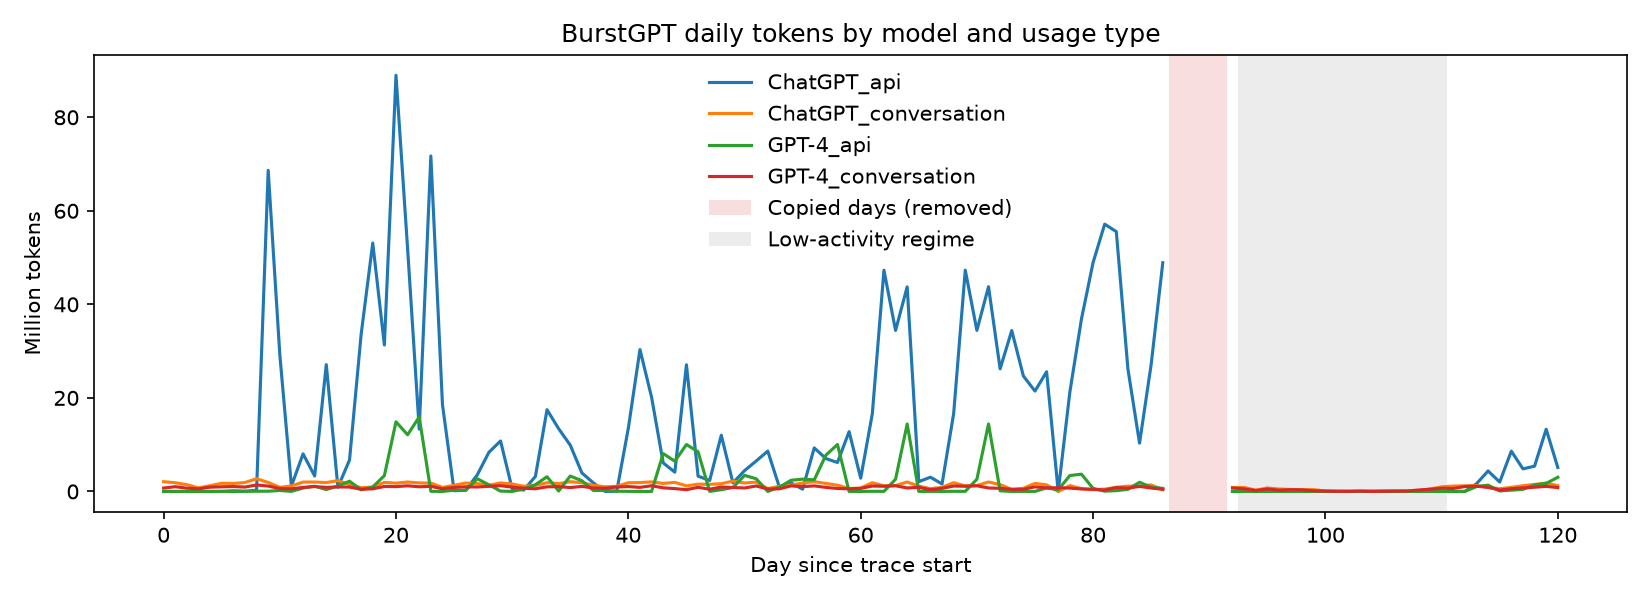

burstgpt_hour_day_heatmap


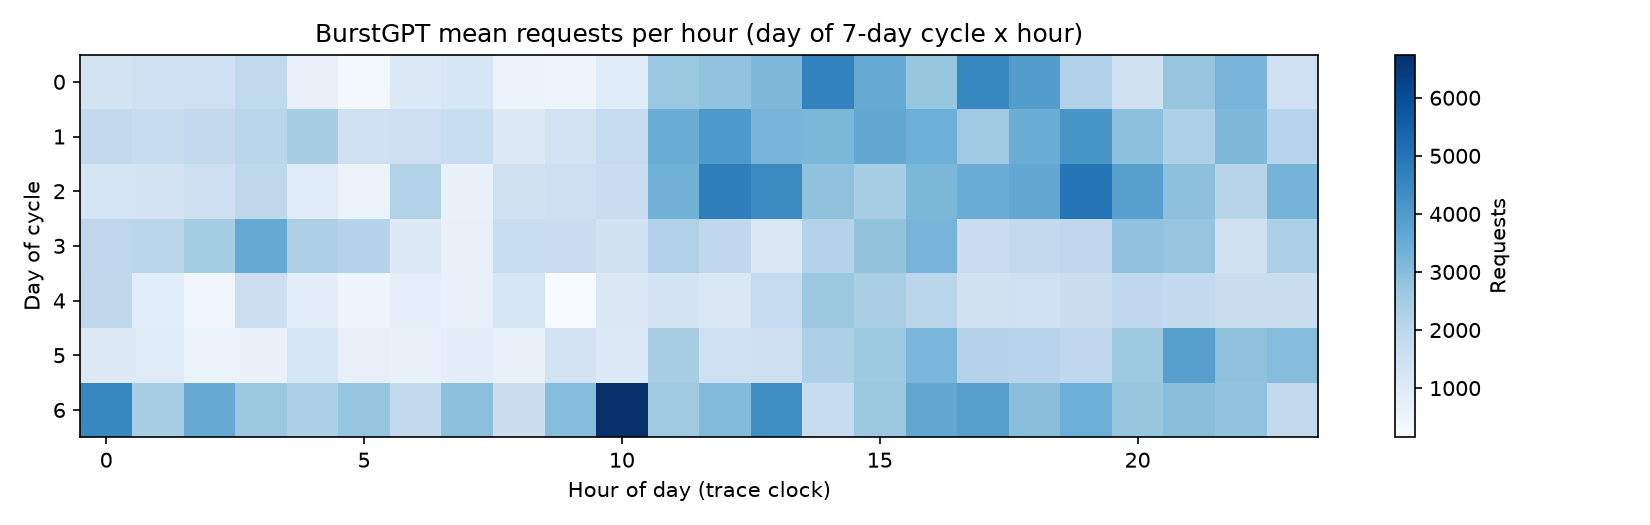

wildchat_weekly


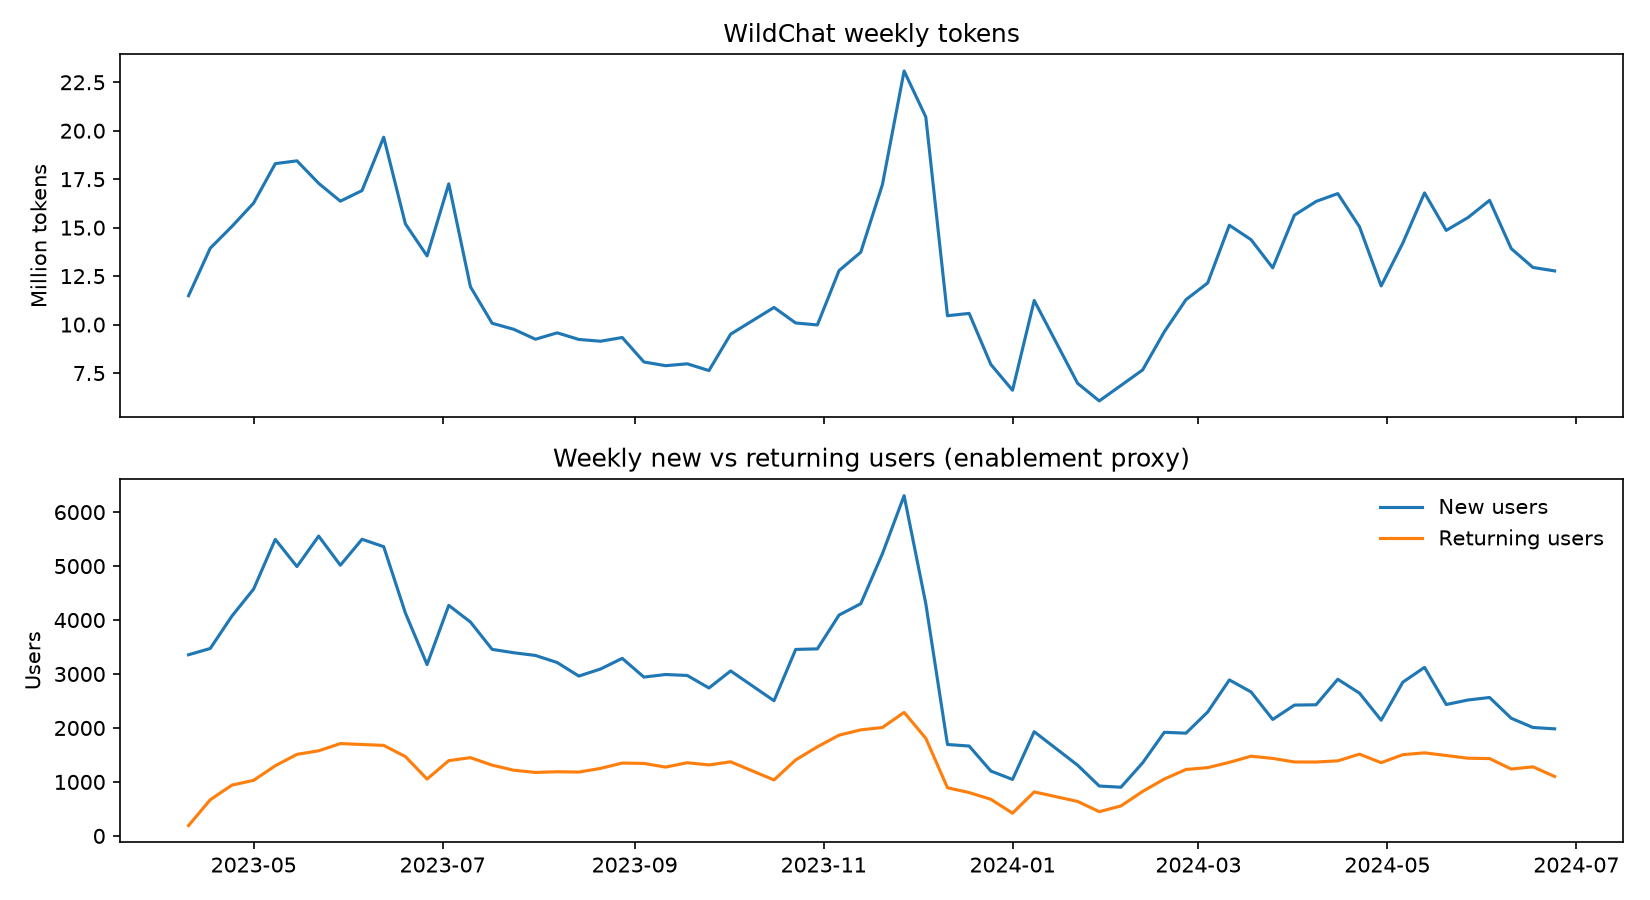

In [8]:
with step("preprocessing figures"):
    figs = sorted(Path("reports/figures").glob("*.png"))
    if not figs:
        print("No preprocessing figures in this bundle; skipped.")
    for f in figs:
        print(f.stem)
        show_img(f, width=800)

# Part B: Phase 1, exploration and baselines

## B1. The series
First we simply look at each series. Shaded areas are flagged days (copied, low activity, outage);
the dashed line marks the start of the **hold-out**, the final stretch we keep aside for a last, fair test.
The table below gives the size and variability: the **coefficient of variation** (CV = standard
deviation / mean) says how bursty a series is (above 1 is very bursty).

,driver,unit,n,mean,std,cv,zero_share,skewness
0,burst_tokens_total_daily,tokens per day,87,2.185054e+07,2.118812e+07,0.970,0.000,1.415
1,burst_tokens_api_daily,tokens per day,87,1.957142e+07,2.122671e+07,1.085,0.000,1.395
2,burst_tokens_chat_daily,tokens per day,87,2.279112e+06,7.205549e+05,0.316,0.000,-0.399
3,burst_requests_hourly,requests per hour,2088,2.193864e+03,3.728942e+03,1.700,0.021,2.821
4,wildchat_conversations_daily,conversations per day,121,2.213041e+03,7.051700e+02,0.319,0.000,2.620
5,eci_wages_quarterly,index,103,1.256470e+02,2.462100e+01,0.196,0.000,0.506
6,ppi_hosting_monthly,index,311,1.088180e+02,6.685000e+00,0.061,0.000,0.971


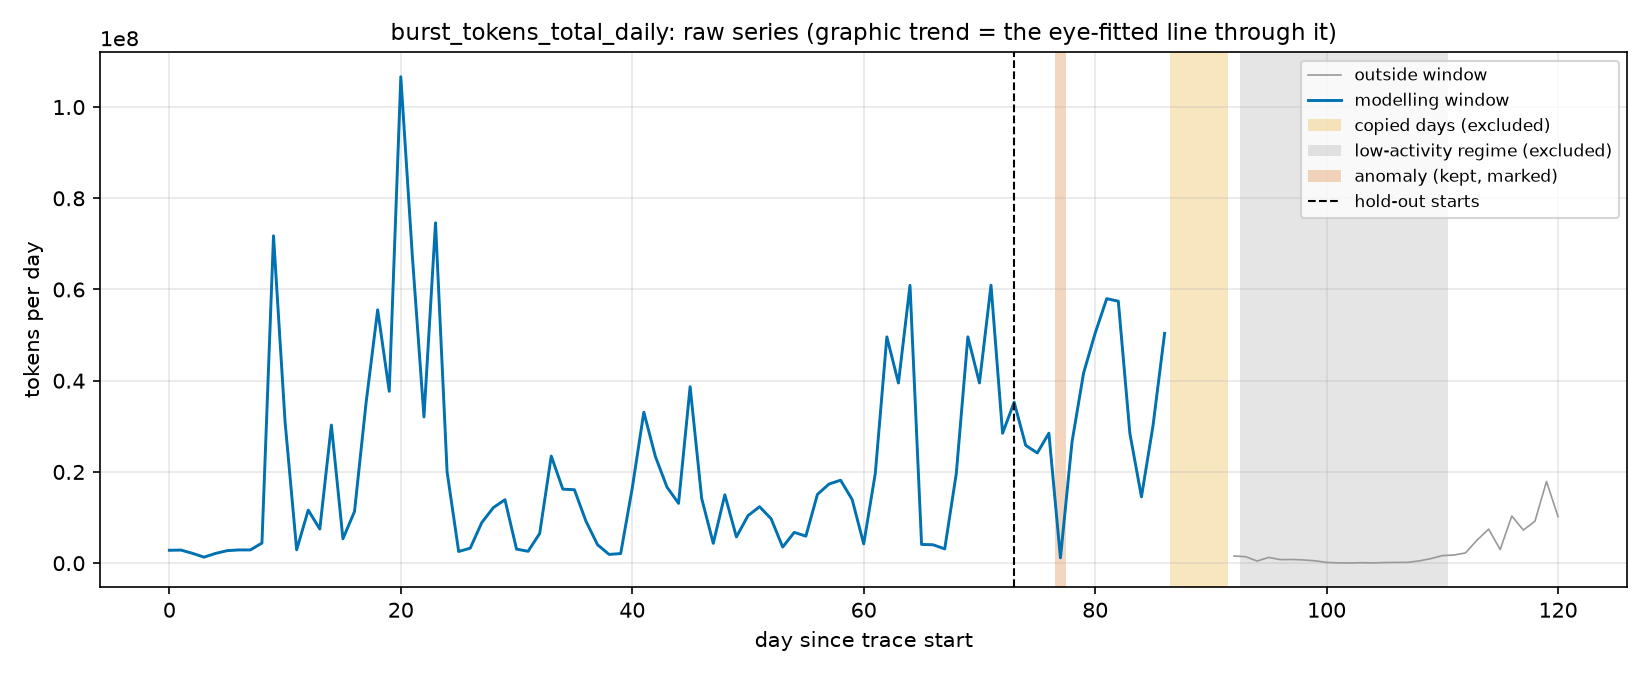

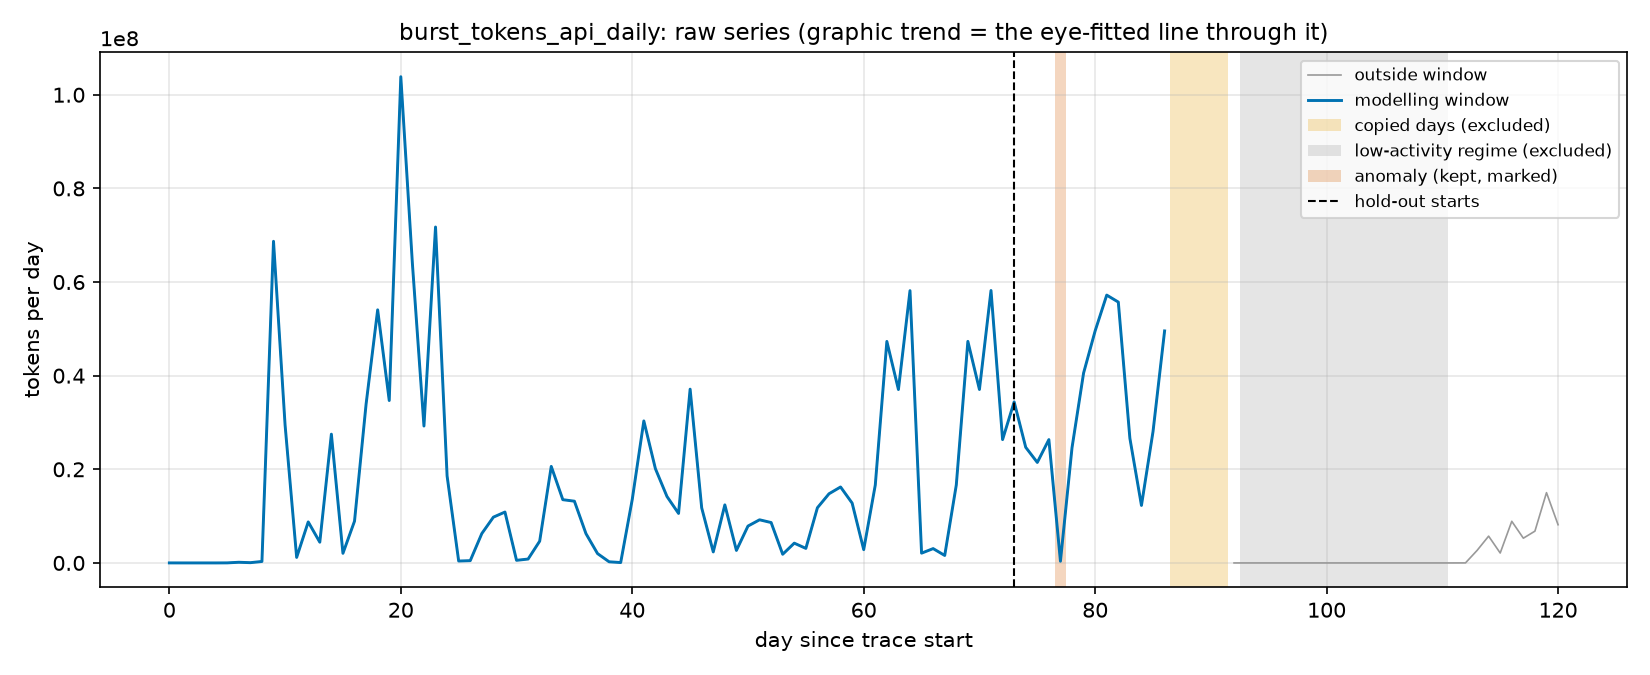

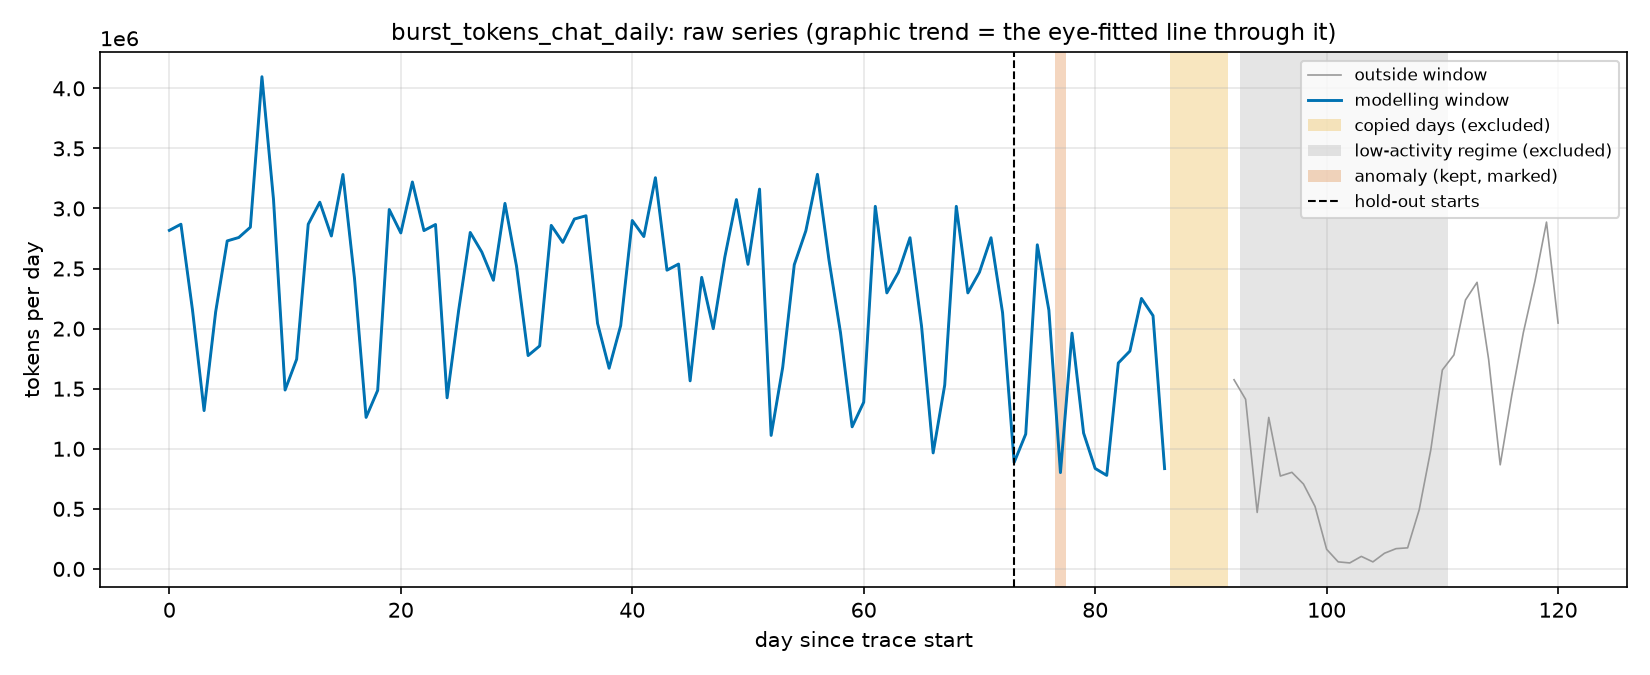

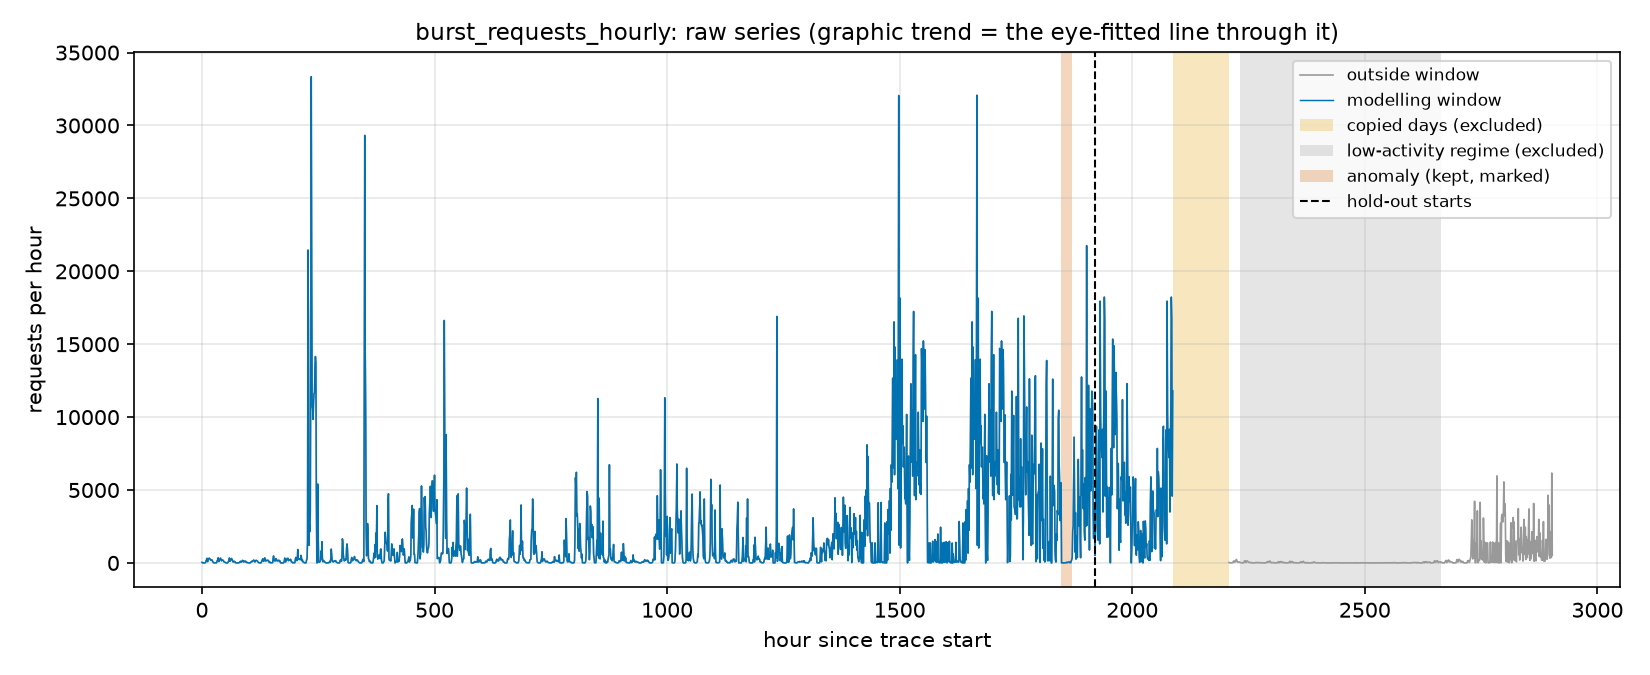

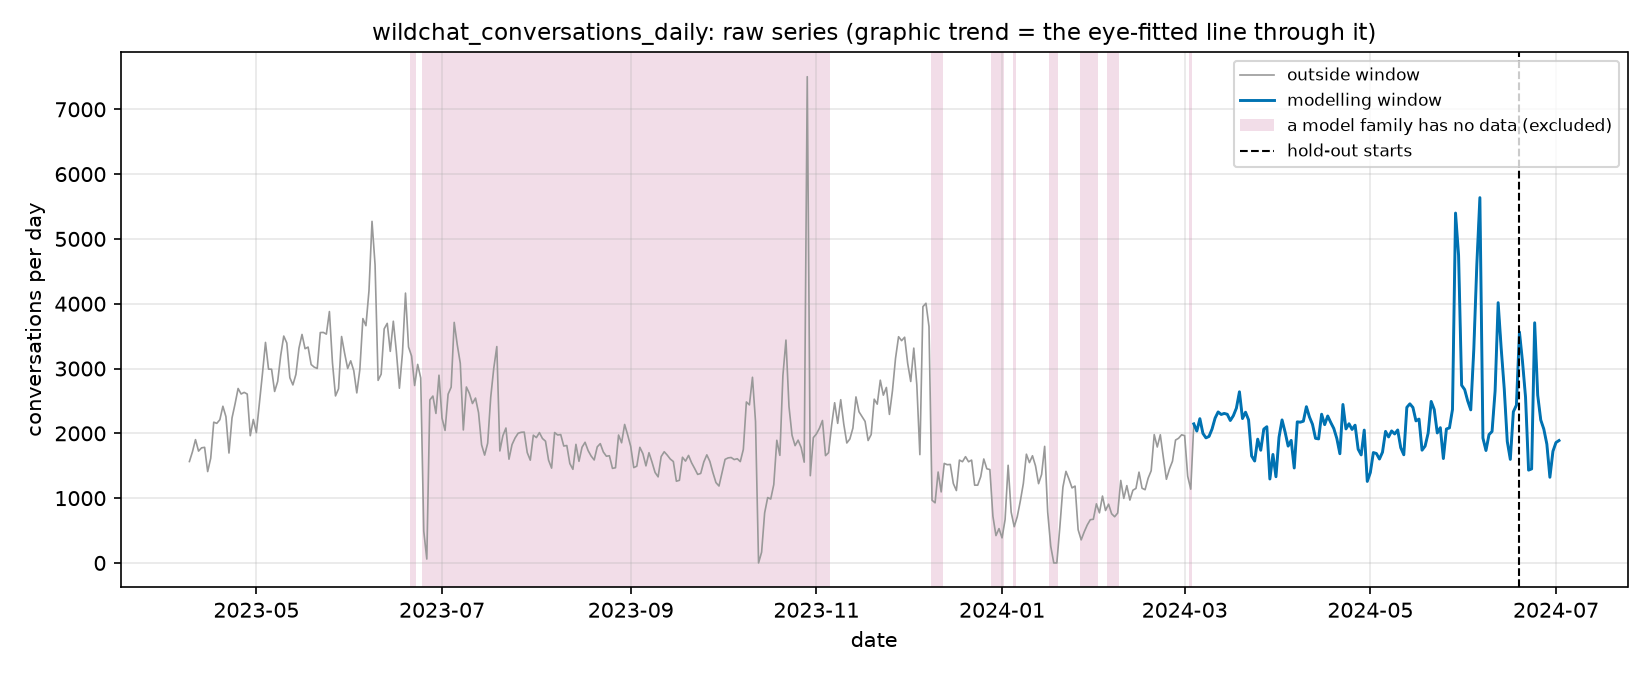

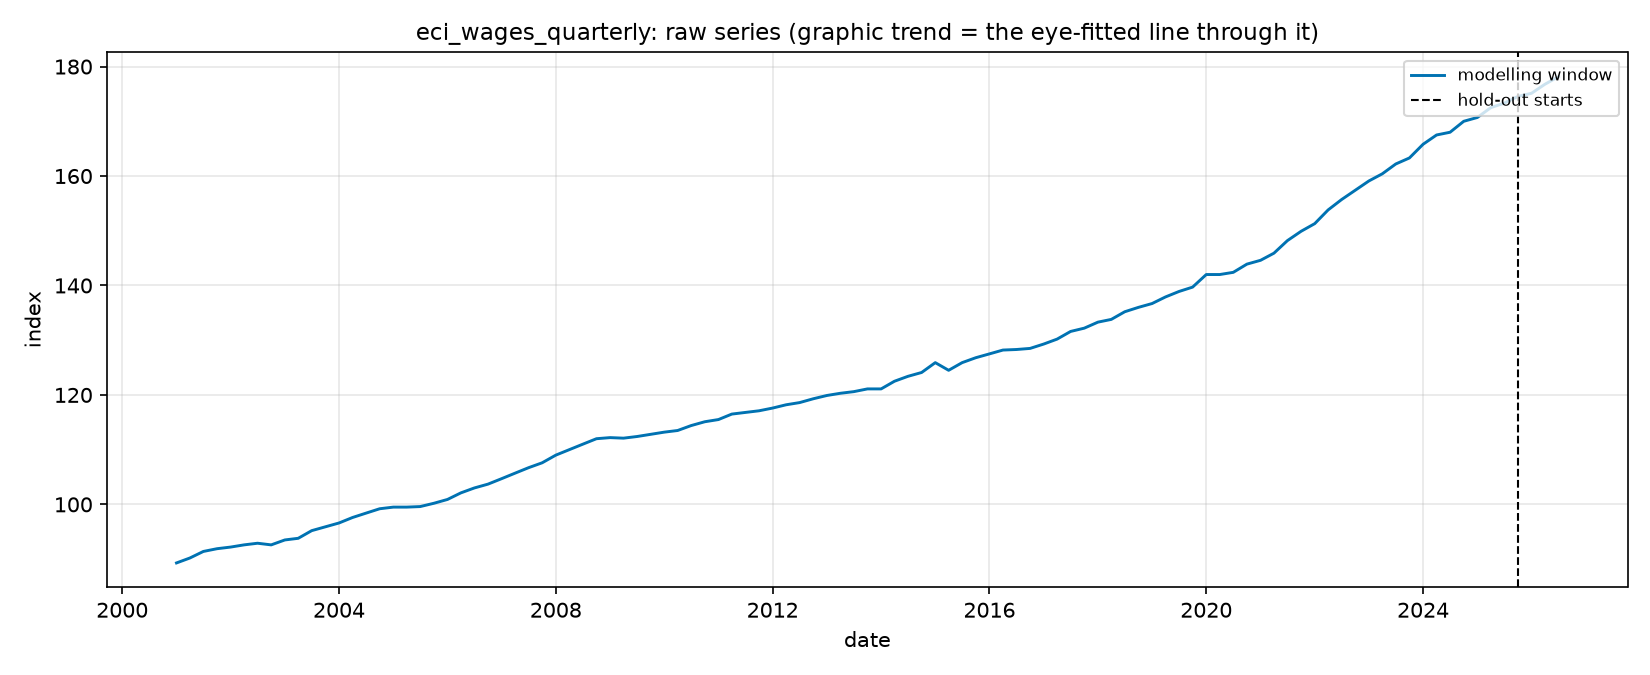

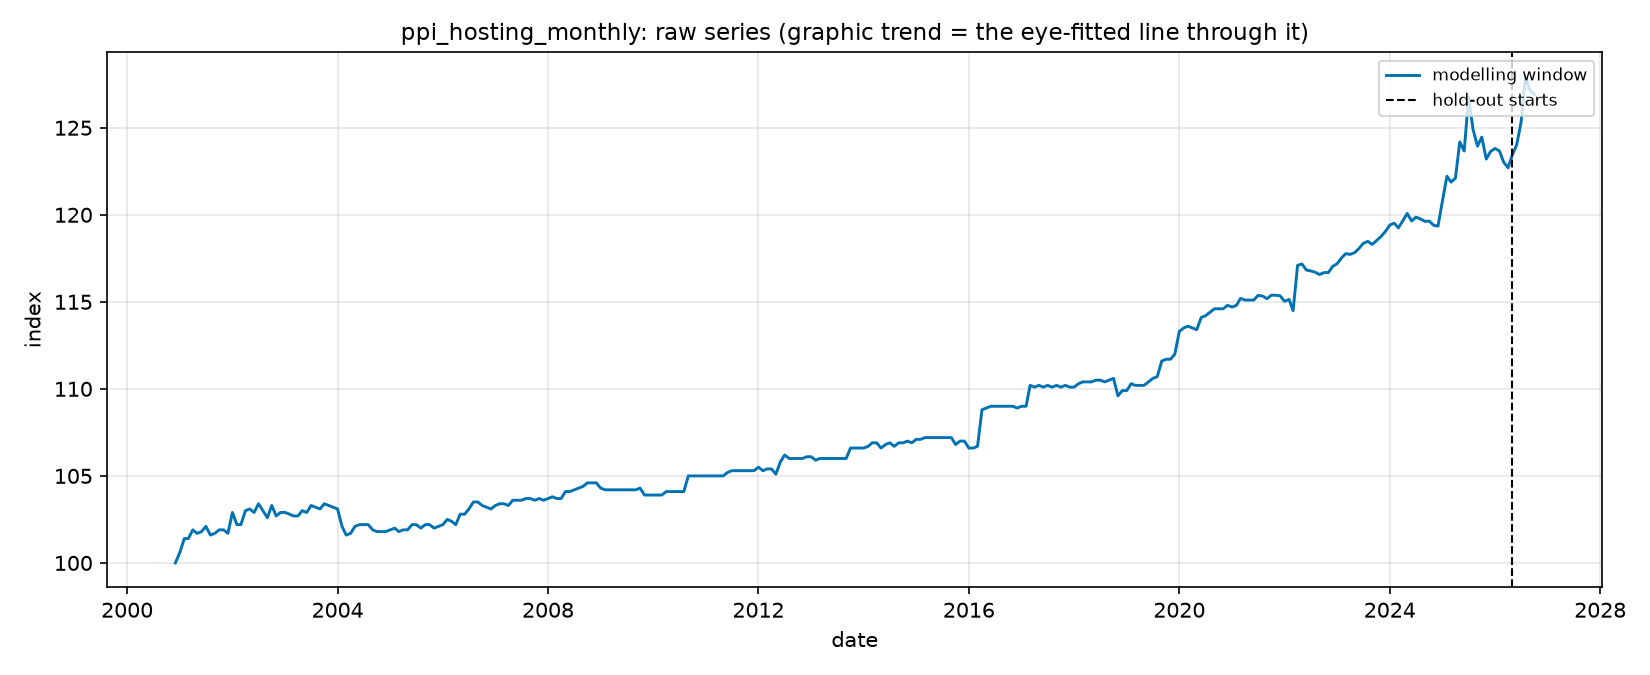

In [9]:
with step("series"):
    show_table(read_table("phase1", "summary_stats"), n=20,
               cols=["driver", "unit", "n", "mean", "std", "cv", "zero_share", "skewness"])
    for name in NAMES:
        show_img(f"outputs/phase1/figures/{name}_series.png", width=850)

## B2. Components: trend, seasonality and remainder
A series = trend + seasonal pattern + remainder (**additive**), or trend x seasonal x remainder
(**multiplicative**, when the swings grow with the level). Our rule: if the rolling standard deviation
rises with the rolling mean (correlation above 0.5), choose multiplicative. **Strength** (0 to 1) says
how much of the variation the trend or the seasonal part explains.

,driver,type,reason,method,seasonal_strength,trend_strength
0,burst_tokens_total_daily,multiplicative,rolling std rises with rolling mean (corr 0.75 > 0.5),STL (robust),0.127,0.368
1,burst_tokens_api_daily,multiplicative,rolling std rises with rolling mean (corr 0.75 > 0.5),STL (robust),0.057,0.683
2,burst_tokens_chat_daily,additive,rolling std does not track rolling mean (corr -0.00 <= 0.5),STL (robust),0.723,0.505
3,burst_requests_hourly,additive,"series has zero or negative values, so multiplicative is not possible","MSTL(24, 168)",0.366,0.384
4,wildchat_conversations_daily,multiplicative,rolling std rises with rolling mean (corr 0.84 > 0.5),STL (robust),0.511,0.491
5,eci_wages_quarterly,multiplicative,rolling std rises with rolling mean (corr 0.67 > 0.5),STL (robust),0.000,1.000
6,ppi_hosting_monthly,multiplicative,rolling std rises with rolling mean (corr 0.63 > 0.5),STL (robust),0.076,0.993


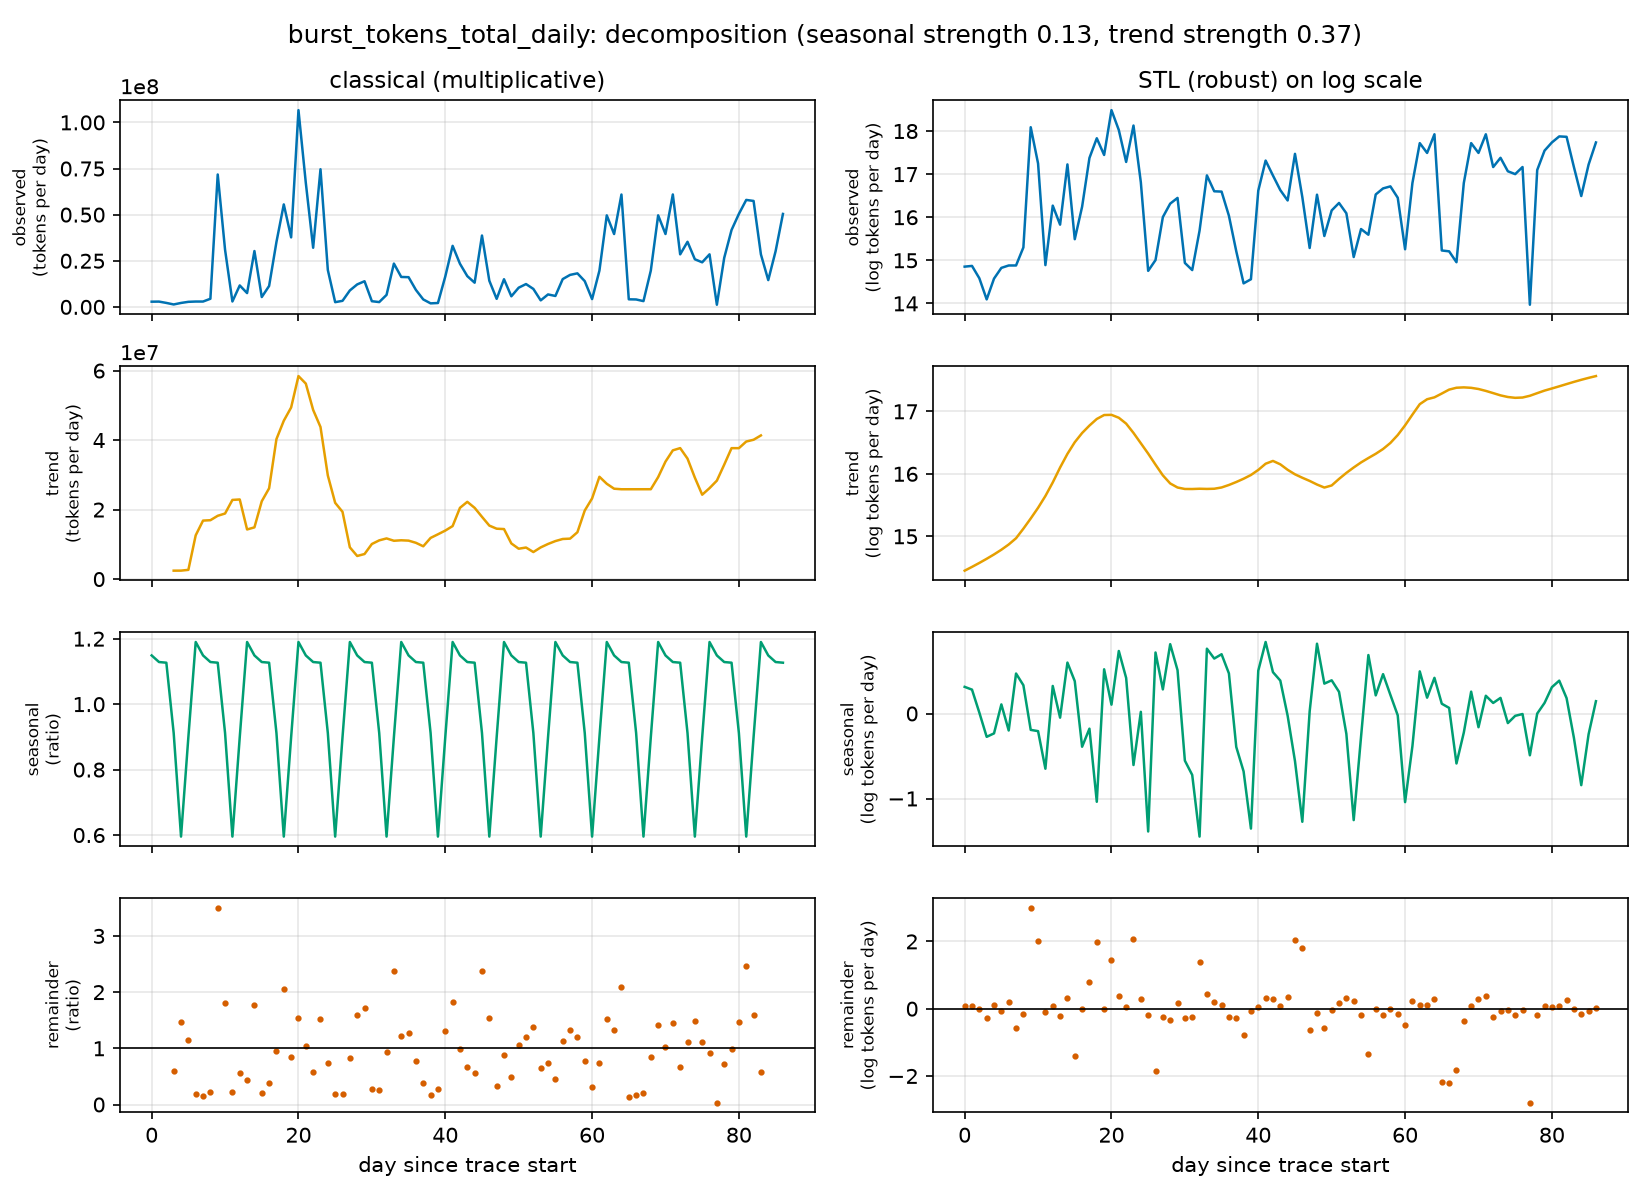

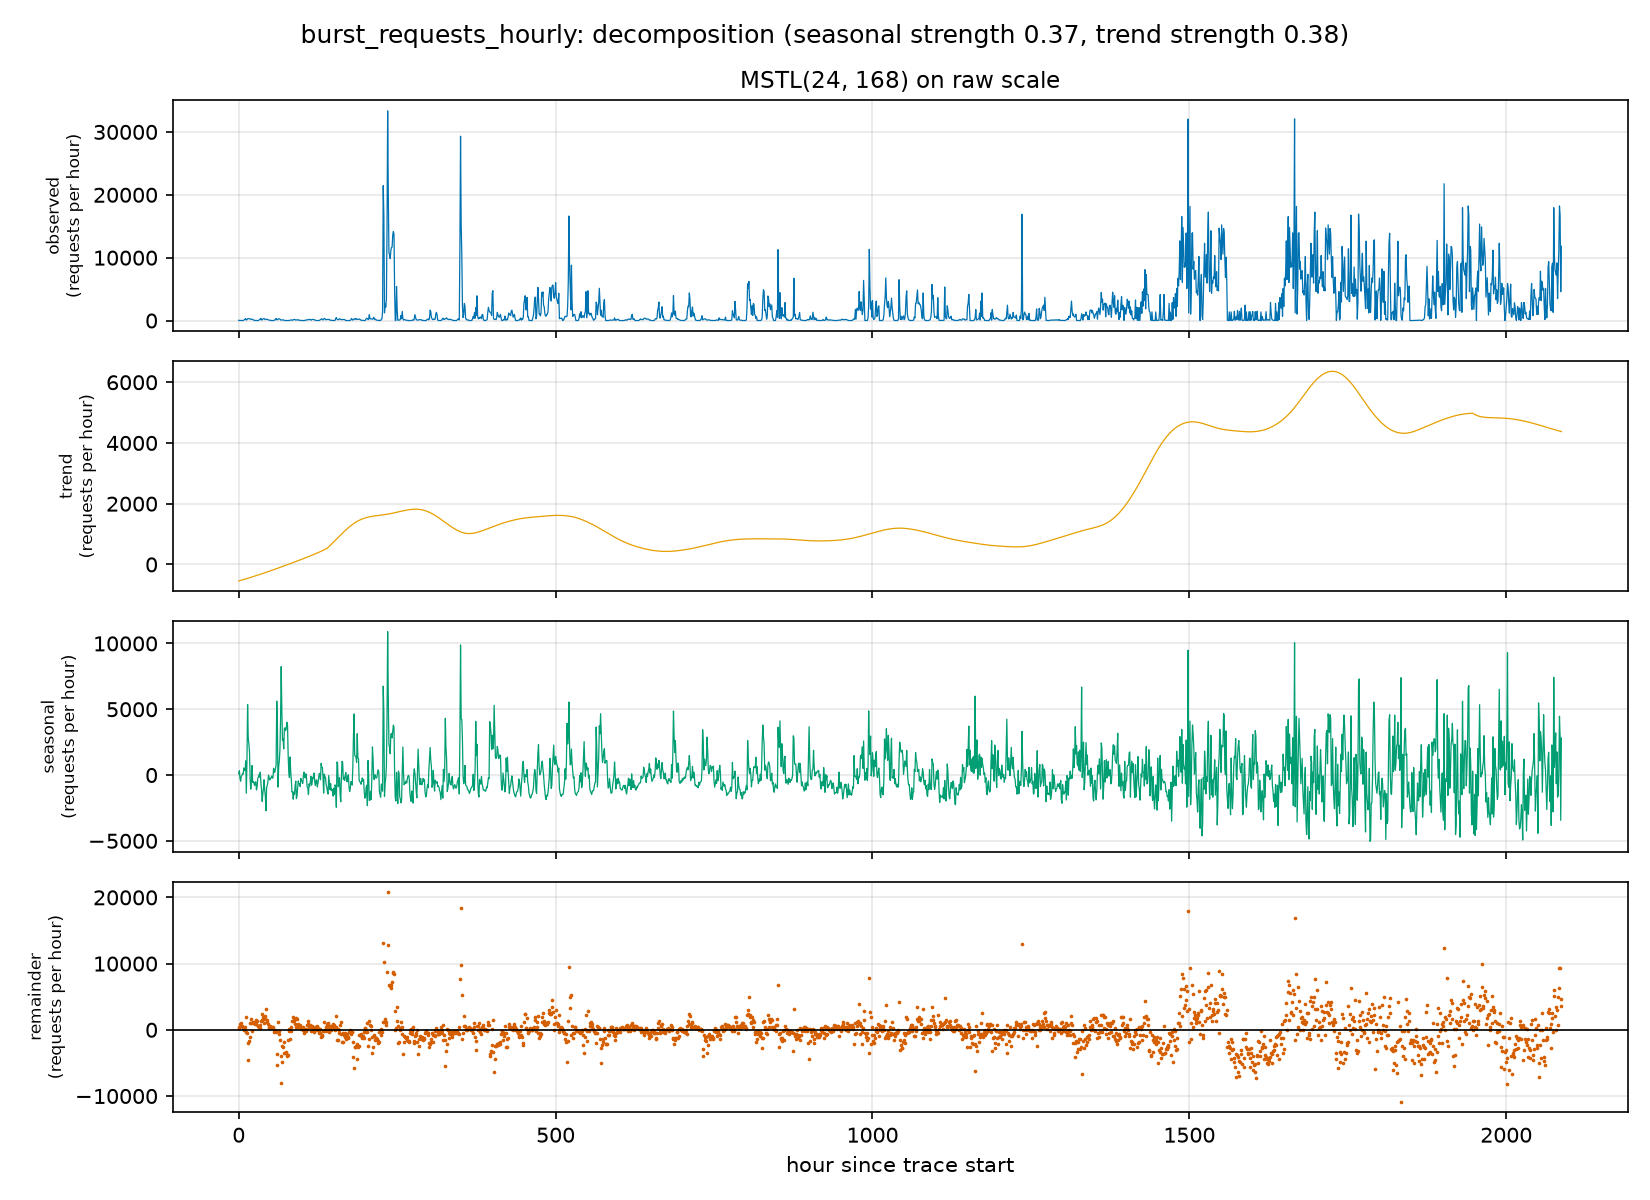

In [10]:
with step("decomposition"):
    show_table(read_table("phase1", "decomposition"), n=20,
               cols=["driver", "type", "reason", "method", "seasonal_strength", "trend_strength"])
    for name in ["burst_tokens_total_daily", "burst_requests_hourly"]:
        show_img(f"outputs/phase1/figures/{name}_decomposition.png", width=850)

## B3. Measuring the trend: four classic methods
On BurstGPT total tokens per day we measure the trend four ways: **semi-averages** (mean of the second
half minus mean of the first half, divided by the distance between their centres), a **centred moving
average**, and **least squares** with a straight line and with a quadratic curve. The slope is in tokens
per day and as a percentage of the mean.

,method,slope_per_step,slope_pct_of_mean,how
0,semi_averages,124918.966,0.572,difference of the two half means / distance between their centres
1,centred_moving_average,140803.756,0.644,least squares slope of the 7-point centred MA
2,least_squares_linear,193462.145,0.885,b in y = a + b t
3,least_squares_quadratic,647357.123,2.963,"slope b + 2ct at the end of the window (t=86), c=5278; at the middle it equals the lin..."


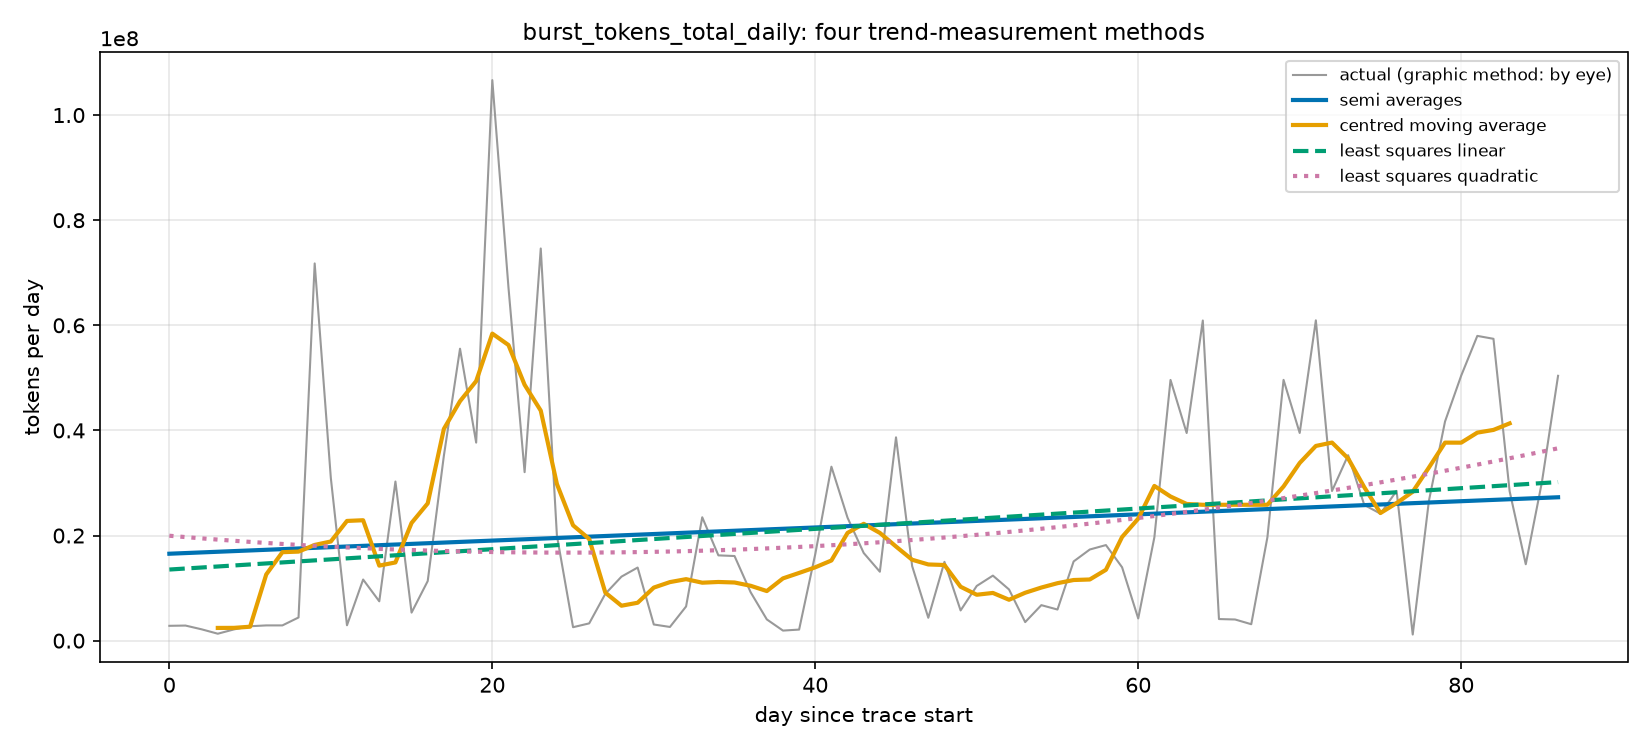

In [11]:
with step("trend methods"):
    show_table(read_table("phase1", "trend_methods"), cols=["method", "slope_per_step", "slope_pct_of_mean", "how"])
    show_img("outputs/phase1/figures/trend_methods_burstgpt.png", width=850)

## B4. Dependence: ACF and PACF
The **ACF** shows how a value correlates with the value k steps earlier; the **PACF** shows the same after
removing the effect of the steps in between. Bars outside the shaded band are significant. A spike at
lag 7 in daily data means a weekly pattern; a slowly decaying ACF means a trend (not stationary).

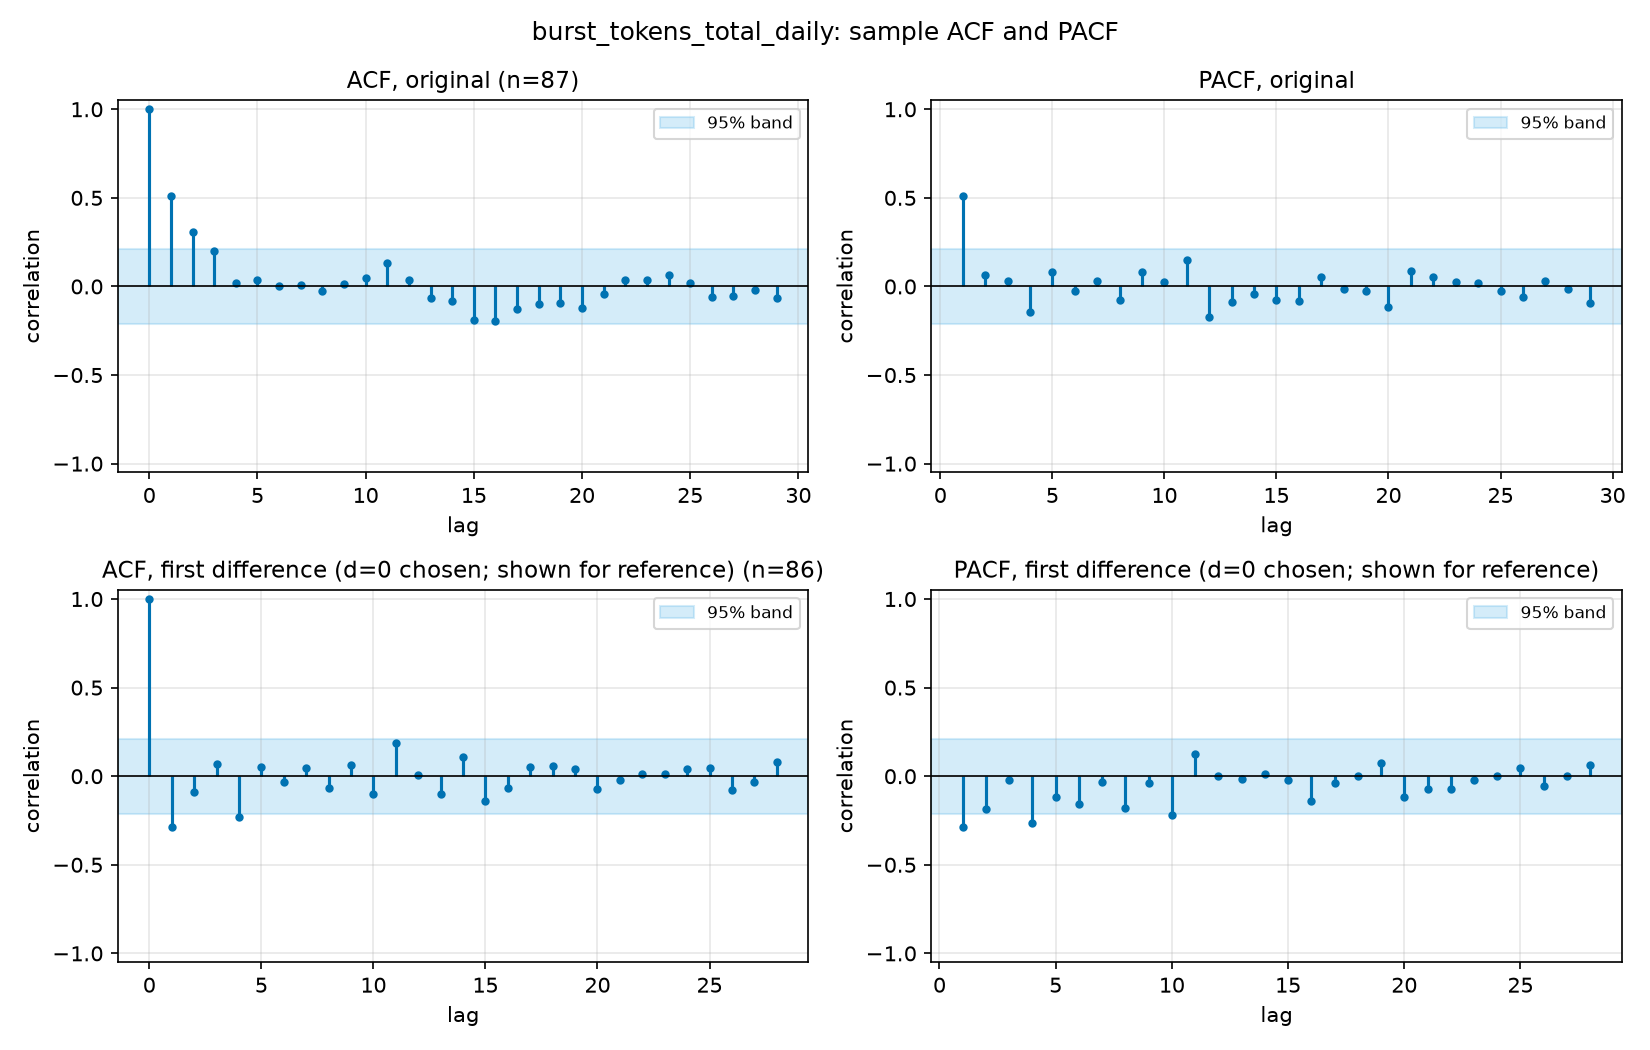

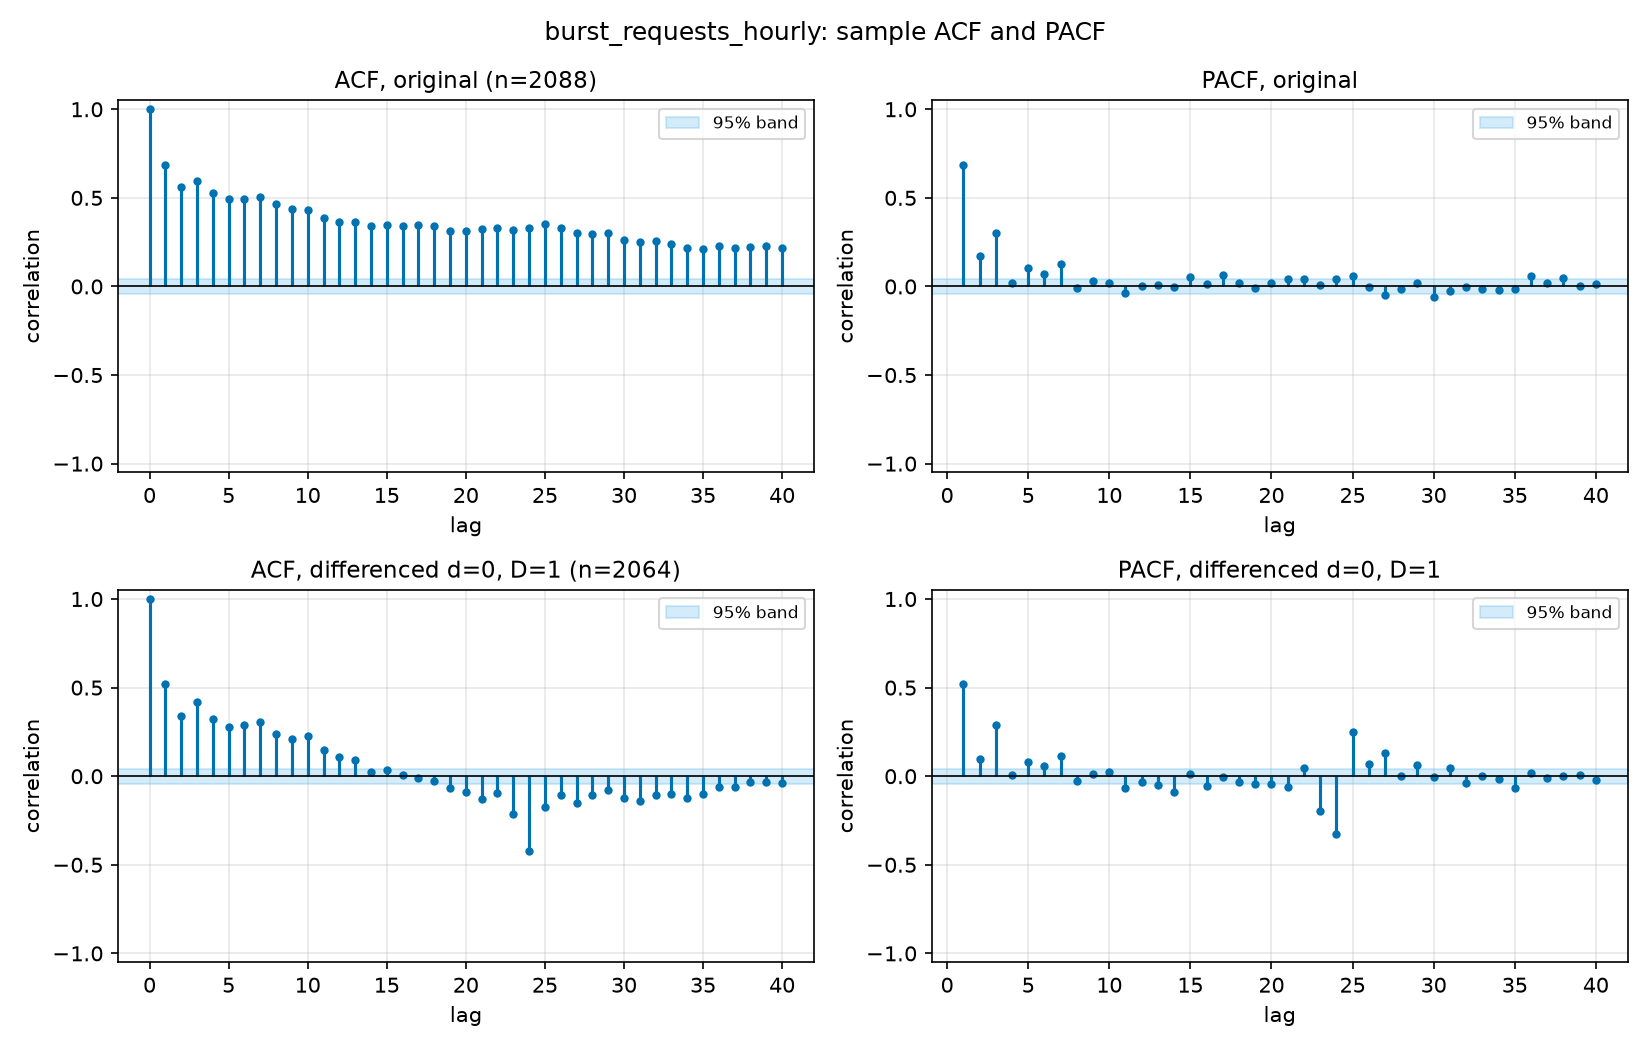

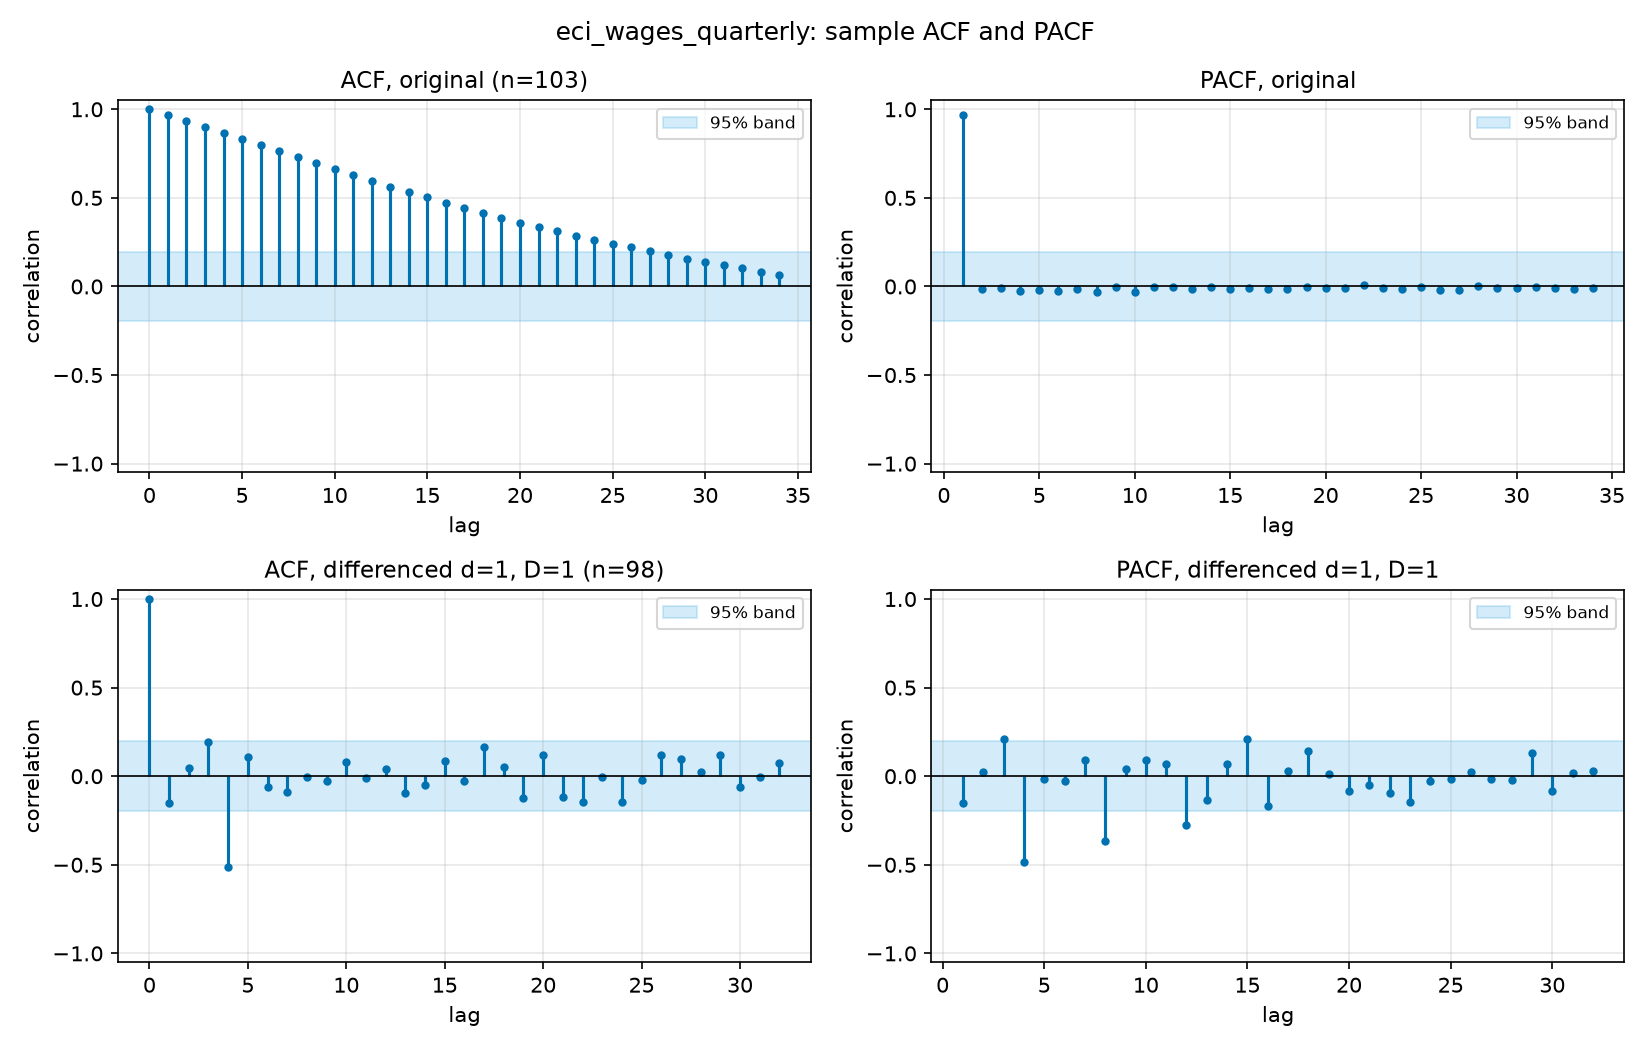

In [12]:
with step("acf pacf"):
    for name in ["burst_tokens_total_daily", "burst_requests_hourly", "eci_wages_quarterly"]:
        show_img(f"outputs/phase1/figures/{name}_acf_pacf.png", width=850)

## B5. Stationarity: ADF and KPSS together
ARIMA needs a **stationary** series (constant mean and variance). The two tests ask opposite questions:
**ADF**: "is there a unit root?" (small p-value = stationary); **KPSS**: "is it stationary?"
(small p-value = not stationary). We difference (d = ordinary, D = seasonal) until both agree the
series is stationary. The decision per driver is carried into Phase 2.

In [13]:
with step("stationarity"):
    show_table(read_table("phase1", "stationarity"), n=25,
               cols=["driver", "d", "D", "adf_stat", "adf_p", "kpss_stat", "kpss_p", "verdict"])
    dec = pd.DataFrame([{k: d[k] for k in ("name", "d", "D", "decomposition", "tests_agree")} for d in HANDOFF["drivers"]])
    print("Decision carried into Phase 2:")
    show_table(dec, n=20)

,driver,d,D,adf_stat,adf_p,kpss_stat,kpss_p,verdict
0,burst_tokens_total_daily,0,0,-5.093,0.000,0.251,0.100,stationary [KPSS p-value at the table bound]
1,burst_tokens_total_daily,0,1,-3.088,0.027,0.070,0.100,stationary [KPSS p-value at the table bound]
2,burst_tokens_total_daily,1,0,-6.618,0.000,0.086,0.100,stationary [KPSS p-value at the table bound]
3,burst_tokens_total_daily,1,1,-5.703,0.000,0.097,0.100,stationary [KPSS p-value at the table bound]
4,burst_tokens_total_daily,2,0,-5.767,0.000,0.157,0.100,stationary [KPSS p-value at the table bound]
5,burst_tokens_api_daily,0,0,-5.069,0.000,0.271,0.100,stationary [KPSS p-value at the table bound]
6,burst_tokens_api_daily,0,1,-3.064,0.029,0.071,0.100,stationary [KPSS p-value at the table bound]
7,burst_tokens_api_daily,1,0,-6.560,0.000,0.086,0.100,stationary [KPSS p-value at the table bound]
8,burst_tokens_api_daily,1,1,-5.689,0.000,0.097,0.100,stationary [KPSS p-value at the table bound]
9,burst_tokens_api_daily,2,0,-5.828,0.000,0.160,0.100,stationary [KPSS p-value at the table bound]


Decision carried into Phase 2:


,name,d,D,decomposition,tests_agree
0,burst_tokens_total_daily,0,0,multiplicative,True
1,burst_tokens_api_daily,0,0,multiplicative,True
2,burst_tokens_chat_daily,0,1,additive,True
3,burst_requests_hourly,0,1,additive,True
4,wildchat_conversations_daily,0,1,multiplicative,True
5,eci_wages_quarterly,1,1,multiplicative,True
6,ppi_hosting_monthly,1,1,multiplicative,True


## B6. Anomaly screen and the day-77 check
We flag a day when its **robust z-score** (distance from the median, measured in MADs, the median
absolute deviation) is above 3.5. The known outage on day 77 is the test case. The result is shown
honestly below, straight from `PHASE1_SUMMARY.md`, including a FAIL if that is what happened.

In [14]:
with step("day 77"):
    an = read_table("phase1", "anomalies")
    show_table(an[an["note"].fillna("").str.contains("day-77")], cols=["driver", "time", "robust_z", "note"])
    text = md_section("outputs/phase1/PHASE1_SUMMARY.md", "day-77")
    display(Markdown(text) if text else Markdown("_No day-77 section in the summary._"))

,driver,time,robust_z,note
0,burst_tokens_total_daily,77,3.158,"day-77 check: FAIL (day 77 not flagged; |robust z| = 3.16 vs threshold 3.5, rank 1 of ..."


Result: **FAIL (day 77 not flagged; |robust z| = 3.16 vs threshold 3.5, rank 1 of 80 days, log scale)**. Day 77 is a one-day outage that preprocessing already marks as `anomaly_low_day` (kept in the series and shaded on every plot). The Phase 1 screen (robust z-score of the seasonal-naive residual, log scale, threshold 3.5) gives day 77 |z| = 3.16, rank 1 of 80 scored days. Most extreme days: day 77 (|z| 3.16), day 30 (|z| 2.88), day 25 (|z| 2.79).

Why it is a finding, not a bug: the screen flags 0 day(s) in total on this series, because the median absolute deviation of the residual is inflated by the bursty API segment (its coefficient of variation is in section 2), so a genuine one-day outage does not stand out from ordinary week-on-week swings. For comparison, the same robust z on the STL remainder (log scale) gives day 77 |z| = 8.18 but flags 15 of 87 days (17%), which is too many to be a useful screen. The threshold was not tuned to force a PASS. Practical consequence: known outages must come from the preprocessing flags, not from a residual screen, and Phase 2 models of BurstGPT tokens should use robust fitting or an outage dummy for day 77.

## B7. Baselines: the bar every later model must beat
Five simple forecasts: **naive** (repeat the last value), **seasonal naive** (repeat the last season),
**mean**, **drift** (straight line from first to last value) and a **seasonal moving average**.
We score them with **MASE**: the forecast error divided by the error of the seasonal naive forecast
on the training data, so **MASE below 1 means better than seasonal naive**.
**Every later model must beat the seasonal naive baseline.**

,rank,driver,best_baseline,cv_mase,holdout_mase,seasonal_naive_cv_mase,n_folds
0,1,burst_tokens_api_daily,mean,0.495,0.909,0.530,4
1,2,burst_tokens_total_daily,mean,0.503,0.873,0.529,4
2,3,eci_wages_quarterly,drift,0.529,0.200,1.737,17
3,4,ppi_hosting_monthly,drift,0.690,2.649,2.109,38
4,5,burst_requests_hourly,seasonal_naive,0.822,2.413,0.822,8
5,6,burst_tokens_chat_daily,seasonal_naive,1.015,2.002,1.015,4
6,7,wildchat_conversations_daily,seasonal_ma3,1.430,2.451,1.507,9


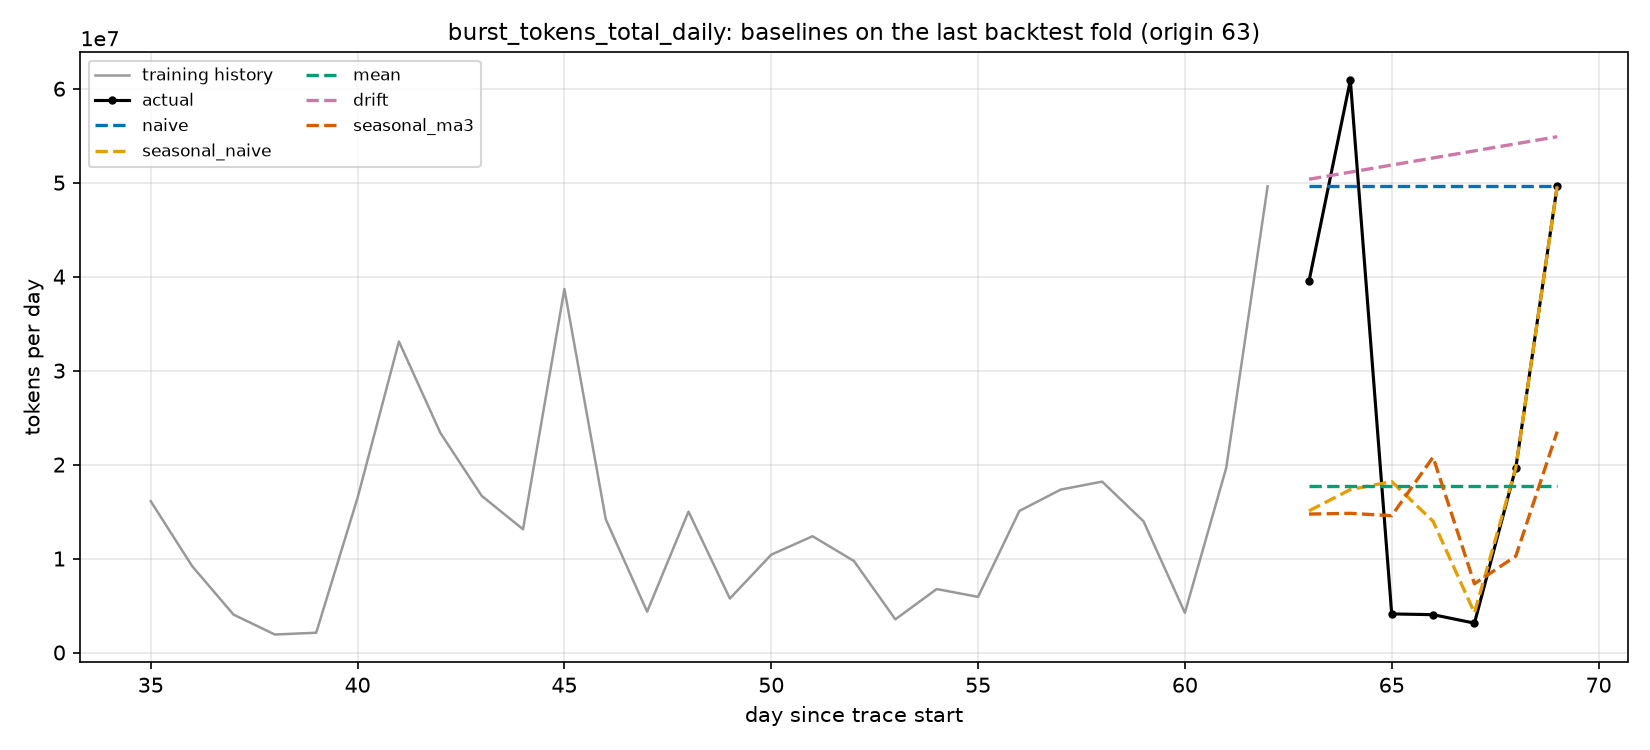

In [15]:
with step("baselines"):
    show_table(read_table("phase1", "leaderboard_baselines"), n=20)
    show_img("outputs/phase1/figures/baselines_burst_tokens_total_daily.png", width=850)

## B8. A look at the code
These cells print real functions from the project with `inspect.getsource`, so you can point to the exact
lines in the review. First **MASE**: the mean absolute error scaled by the in-sample error of seasonal naive.

In [16]:
import importlib, inspect

def show_source(module, func, max_lines=25):
    """Print the source of module.func (first max_lines lines), or a short message."""
    try:
        obj = getattr(importlib.import_module(module), func)
        lines = inspect.getsource(obj).splitlines()
    except Exception as exc:
        print(f"Could not find {module}.{func}: {type(exc).__name__}; skipped.")
        return
    more = f"\n# ... {len(lines) - max_lines} more lines" if len(lines) > max_lines else ""
    display(Markdown(f"`{module}.{func}`\n```python\n" + "\n".join(lines[:max_lines]) + more + "\n```"))

with step("code: mase"):
    show_source("tsaf.metrics", "mase_scale")
    show_source("tsaf.metrics", "mase")

`tsaf.metrics.mase_scale`
```python
def mase_scale(train, season: int | None) -> float:
    """In-sample MAE of the seasonal naive forecast (naive when season is None or 1)."""
    y = _arr(train)
    m = season if season and season > 1 else 1
    if len(y) <= m:
        return float("nan")
    return float(np.mean(np.abs(y[m:] - y[:-m])))
```

`tsaf.metrics.mase`
```python
def mase(actual, forecast, train, season: int | None) -> float:
    """Mean absolute scaled error; NaN when the scale is 0 or cannot be computed."""
    scale = mase_scale(train, season)
    if not np.isfinite(scale) or scale == 0:
        return float("nan")
    return mae(actual, forecast) / scale
```

**Semi-averages trend**: split the series in two halves, take each half's mean, and divide the
difference by the distance between the two half centres.

In [17]:
with step("code: semi-averages"):
    show_source("tsaf.eda", "semi_averages")

`tsaf.eda.semi_averages`
```python
def semi_averages(y: np.ndarray) -> tuple[float, float]:
    """Semi-average trend: (slope, intercept). With odd n the middle point is dropped."""
    y = np.asarray(y, dtype=float)
    t = np.arange(len(y), dtype=float)
    half = len(y) // 2
    t1, y1 = t[:half], y[:half]
    t2, y2 = t[len(y) - half:], y[len(y) - half:]
    slope = (y2.mean() - y1.mean()) / (t2.mean() - t1.mean())
    return float(slope), float(y1.mean() - slope * t1.mean())
```

**Rolling-origin backtest**: every fold trains only on the data before its origin and tests on the next
h points; the origin then moves forward by `step`. No shuffling, so the future never leaks into training.

In [18]:
with step("code: rolling origin"):
    show_source("tsaf.backtest", "rolling_origin")

`tsaf.backtest.rolling_origin`
```python
def rolling_origin(series: pd.Series, forecaster: Callable, h: int, initial: int, step: int,
                   max_folds: int | None, season: int | None) -> pd.DataFrame:
    """Run `forecaster` over expanding-window folds; tidy rows per fold and step ahead."""
    rows = []
    for fold, origin in enumerate(fold_origins(len(series), initial, h, step, max_folds)):
        train, test = series.iloc[:origin], series.iloc[origin:origin + h]
        fc = np.asarray(forecaster(train, h, season), dtype=float)
        for k in range(h):
            rows.append({"fold": fold, "step_ahead": k + 1, "origin_index": origin,
                         "time": test.index[k], "actual": float(test.iloc[k]),
                         "forecast": float(fc[k])})
    cols = ["fold", "step_ahead", "origin_index", "time", "actual", "forecast"]
    return pd.DataFrame(rows, columns=cols)
```

# Part C: Phase 2, forecasting models

## C1. The model families
- **baseline**: the five Phase 1 benchmarks.
- **smoothing**: moving average and exponential smoothing (SES, Holt, damped Holt, Holt-Winters), which weight recent values more.
- **arima**: ARIMA, seasonal SARIMA, and SARIMAX with extra inputs (weekend dummy, or Fourier sine/cosine terms for hourly data).
- **ml**: Ridge regression, random forest and XGBoost on lag features, forecasting one step at a time.
- **deep**: optional Prophet and LSTM challengers.
- **ensemble**: the average of the two best models.

The table lists every registered model and the series it actually ran on (from the leaderboard).

In [19]:
with step("families"):
    from tsaf.models.registry import build_registry
    lb = read_table("phase2", "leaderboard")
    rows = []
    for model, family in [(s.name, s.family) for s in build_registry()] + [("ensemble", "ensemble")]:
        ok = lb[(lb["model"] == model) & (lb["status"] == "ok")]["driver"].tolist()
        rows.append({"family": family, "model": model,
                     "ran on": f"{len(ok)} series" + (f": {', '.join(ok)}" if 0 < len(ok) < 4 else "")
                     if ok else "not run (reason in leaderboard.csv)"})
    show_table(pd.DataFrame(rows), n=40)

,family,model,ran on
0,baseline,naive,7 series
1,baseline,seasonal_naive,7 series
2,baseline,mean,7 series
3,baseline,drift,7 series
4,baseline,seasonal_ma3,7 series
5,smoothing,moving_average,7 series
6,smoothing,ses,7 series
7,smoothing,holt,7 series
8,smoothing,damped_holt,7 series
9,smoothing,hw_additive,7 series


## C2. How the models are compared
Every model gets **exactly the same test**: an *expanding-window rolling-origin backtest*. The training
window (blue) grows, the test window (orange) moves forward, and the **hold-out** at the end (grey) is
used once, at the very end, never for choosing. The diagram uses the real settings of BurstGPT daily
tokens. A model "wins" a series only if its mean cross-validation (CV) **MASE** is below seasonal naive's.

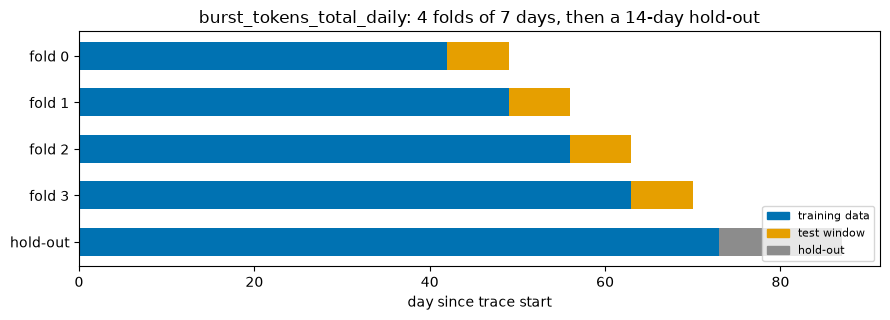

In [20]:
with step("backtest diagram"):
    import matplotlib.pyplot as plt
    from tsaf import backtest
    d = next(x for x in HANDOFF["drivers"] if x["grain"] == "daily")
    cv, n = d["cv_settings"], d["n_obs"]
    origins = backtest.fold_origins(n - cv["holdout"], cv["initial"], cv["h"], cv["step"])
    fig, ax = plt.subplots(figsize=(9, 0.55 * (len(origins) + 2)))
    for i, o in enumerate(origins):
        ax.barh(i, o, color="#0072B2", height=0.6)
        ax.barh(i, cv["h"], left=o, color="#E69F00", height=0.6)
    k = len(origins)
    ax.barh(k, n - cv["holdout"], color="#0072B2", height=0.6)
    ax.barh(k, cv["holdout"], left=n - cv["holdout"], color="#8C8C8C", height=0.6)
    ax.set_yticks(range(k + 1), [f"fold {i}" for i in range(k)] + ["hold-out"])
    ax.invert_yaxis()
    ax.set_xlabel("day since trace start")
    ax.set_title(f"{d['name']}: {k} folds of {cv['h']} days, then a {cv['holdout']}-day hold-out")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#0072B2", "#E69F00", "#8C8C8C")],
              labels=["training data", "test window", "hold-out"], loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

## C3. Leaderboards
For each series: bars of mean CV MASE per model (shorter is better), the dashed line is seasonal naive,
the blue bar is the chosen model. The table shows the top 5 with the **share of folds** in which the
model beat seasonal naive and its **hold-out MASE** (the final, untouched test).

**burst_tokens_total_daily**

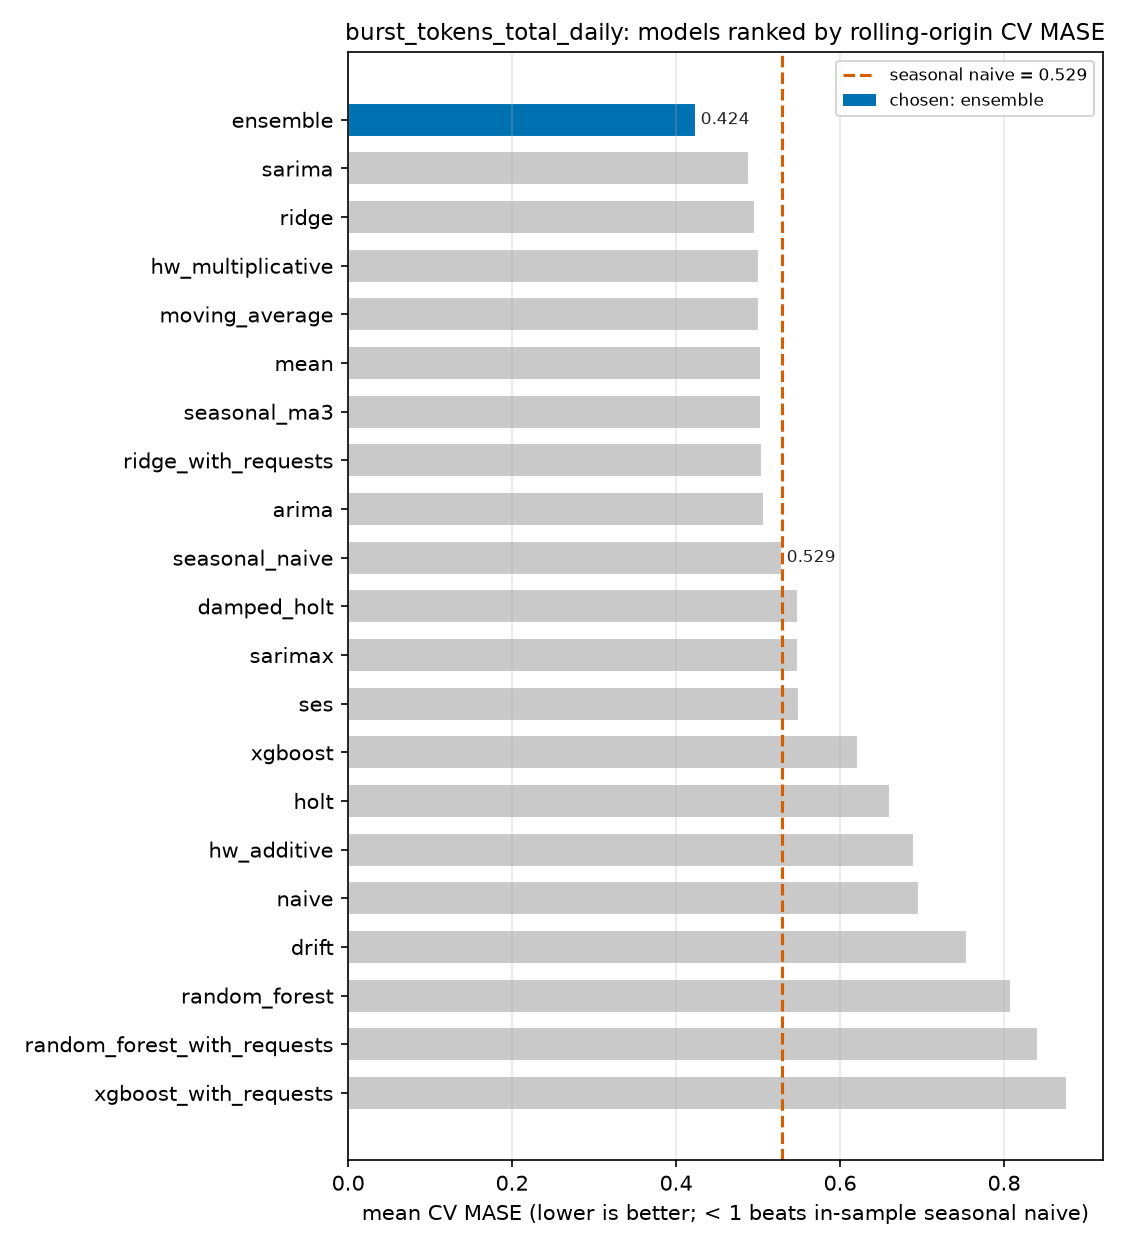

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.424,0.75,1.003
1,sarima,arima,0.489,0.50,0.911
2,ridge,ml,0.496,0.50,1.095
3,hw_multiplicative,smoothing,0.502,0.50,1.057
4,moving_average,smoothing,0.502,0.50,0.775


**burst_tokens_api_daily**

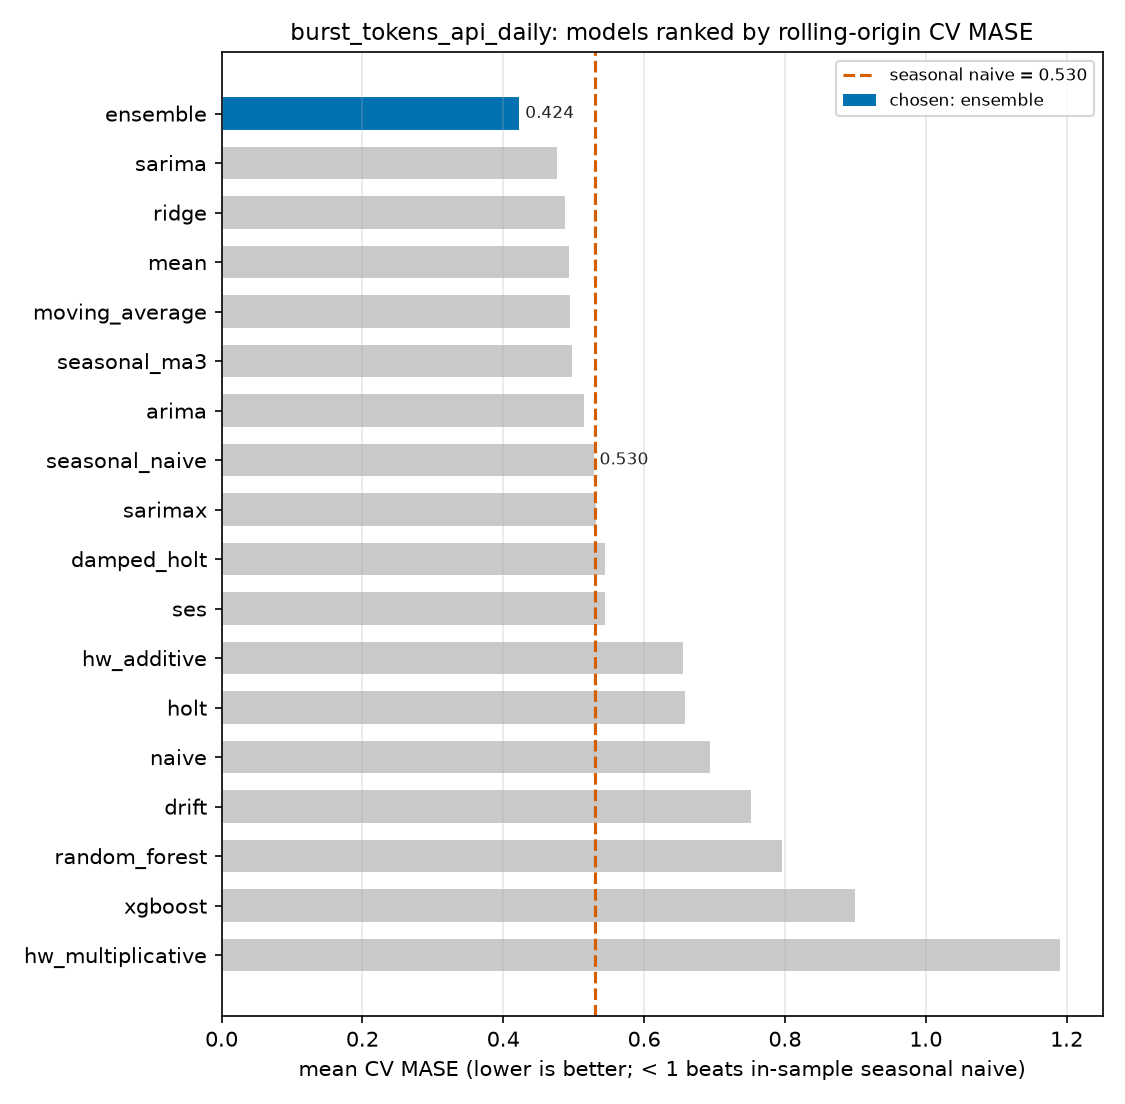

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.424,0.75,1.030
1,sarima,arima,0.478,0.50,0.948
2,ridge,ml,0.489,0.50,1.113
3,mean,baseline,0.495,0.50,0.909
4,moving_average,smoothing,0.496,0.50,0.770


**burst_tokens_chat_daily**

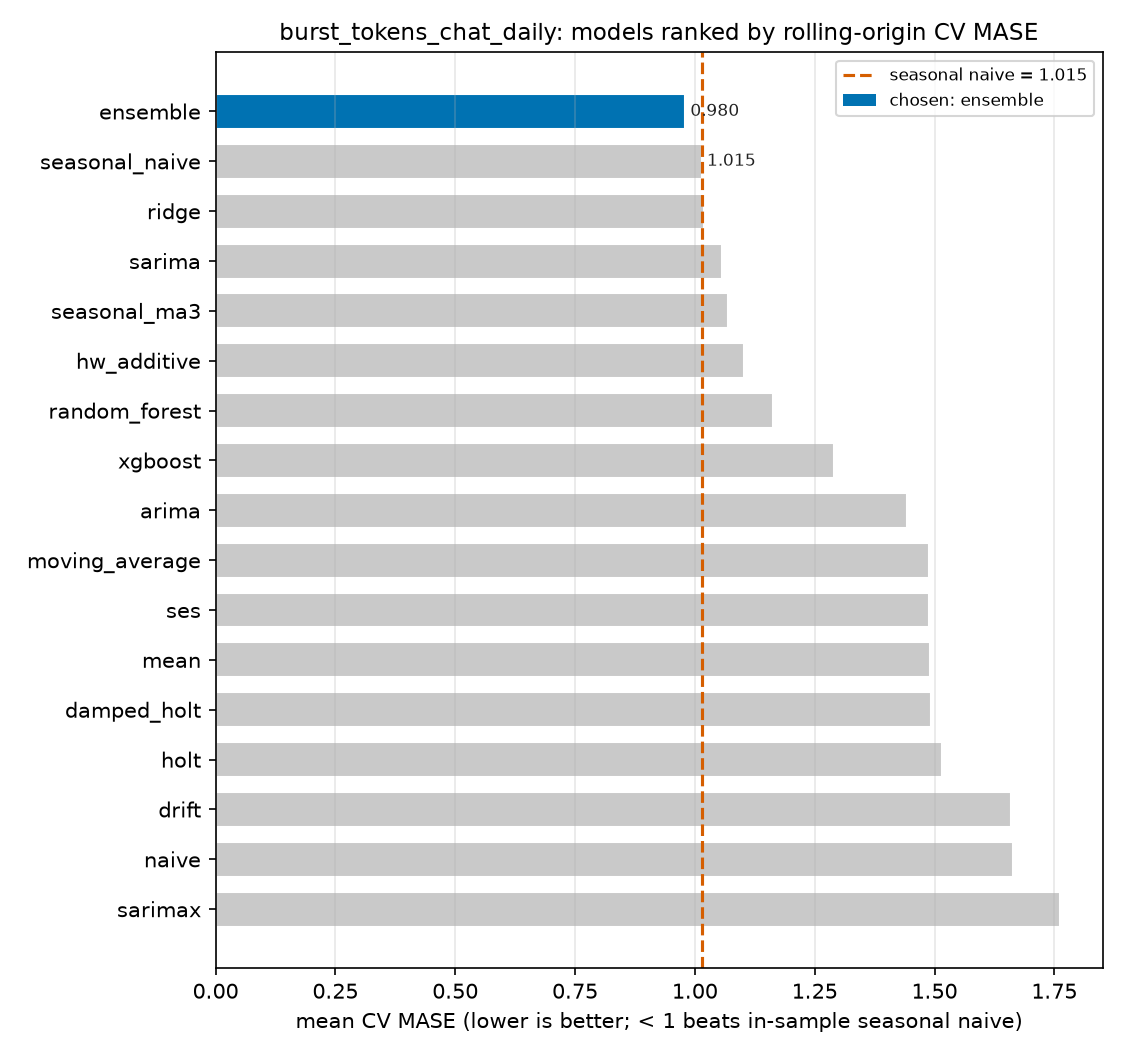

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.980,0.75,2.001
1,seasonal_naive,baseline,1.015,0.00,2.002
2,ridge,ml,1.019,0.75,2.035
3,sarima,arima,1.056,0.50,2.044
4,seasonal_ma3,baseline,1.069,0.75,2.109


**burst_requests_hourly**

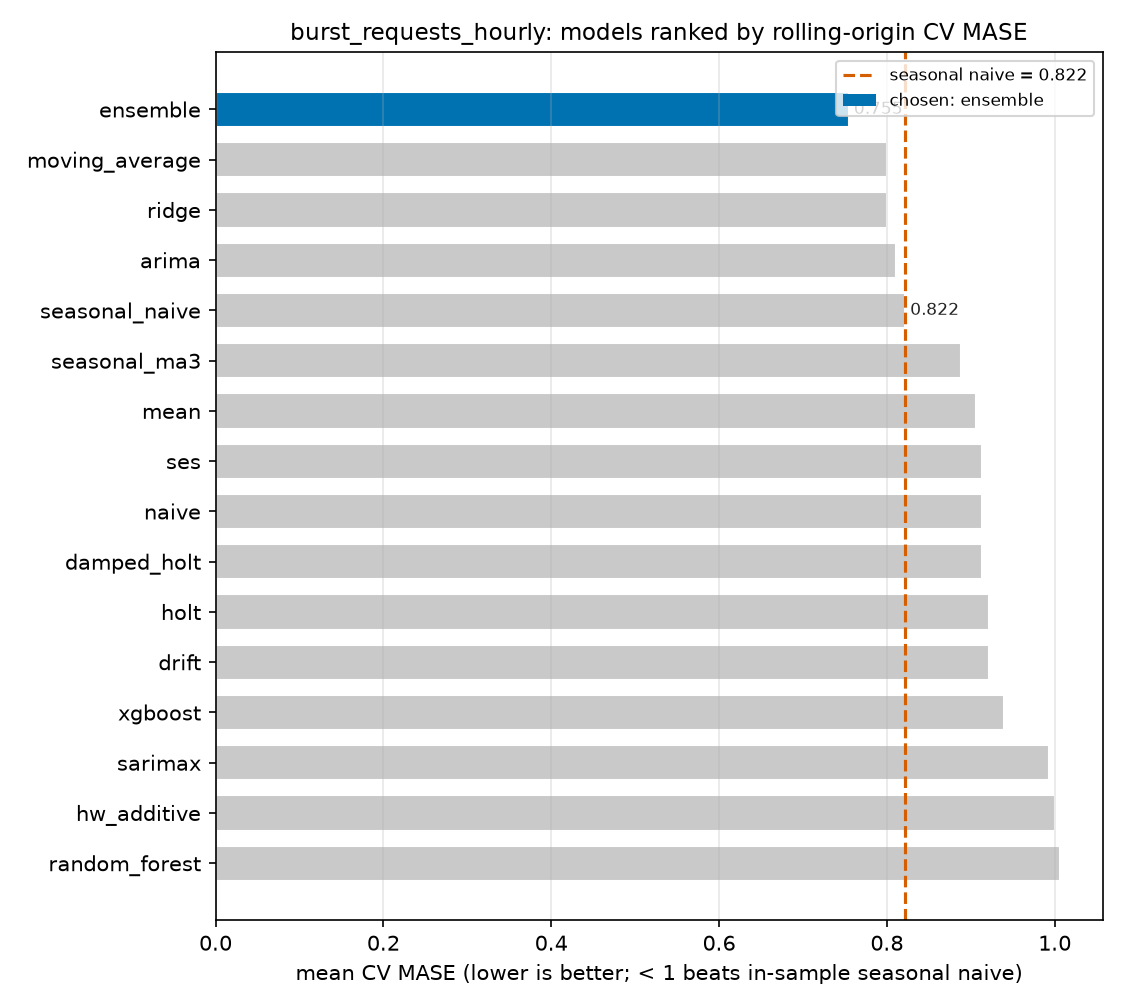

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.755,0.750,1.834
1,moving_average,smoothing,0.800,0.375,1.921
2,ridge,ml,0.800,0.625,1.782
3,arima,arima,0.810,0.375,1.677
4,seasonal_naive,baseline,0.822,0.000,2.413


**wildchat_conversations_daily**

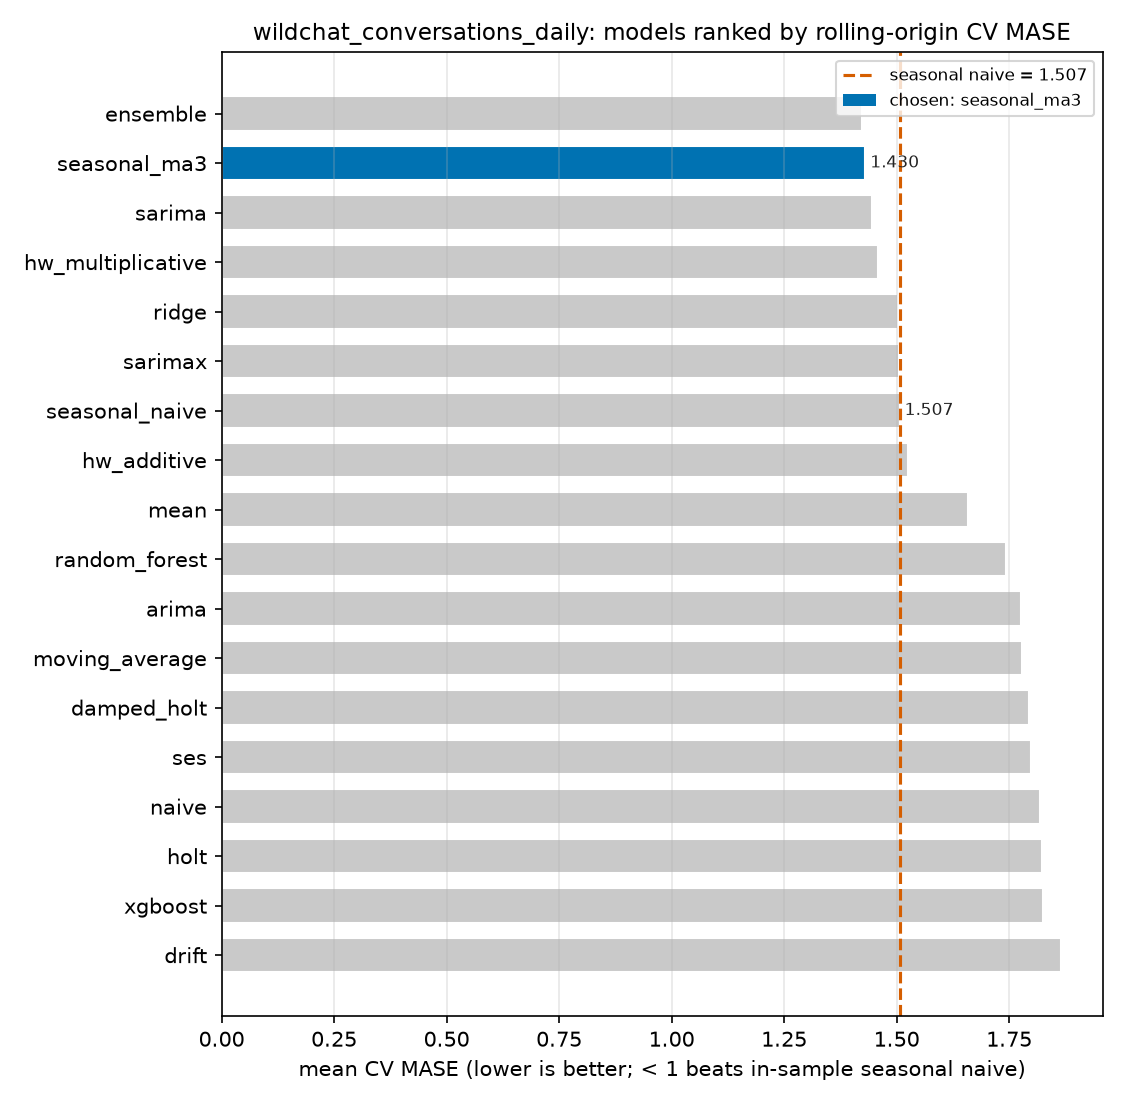

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,1.423,0.333,2.071
1,seasonal_ma3,baseline,1.430,0.222,2.451
2,sarima,arima,1.445,0.444,1.692
3,hw_multiplicative,smoothing,1.459,0.556,1.745
4,ridge,ml,1.503,0.556,1.770


**eci_wages_quarterly**

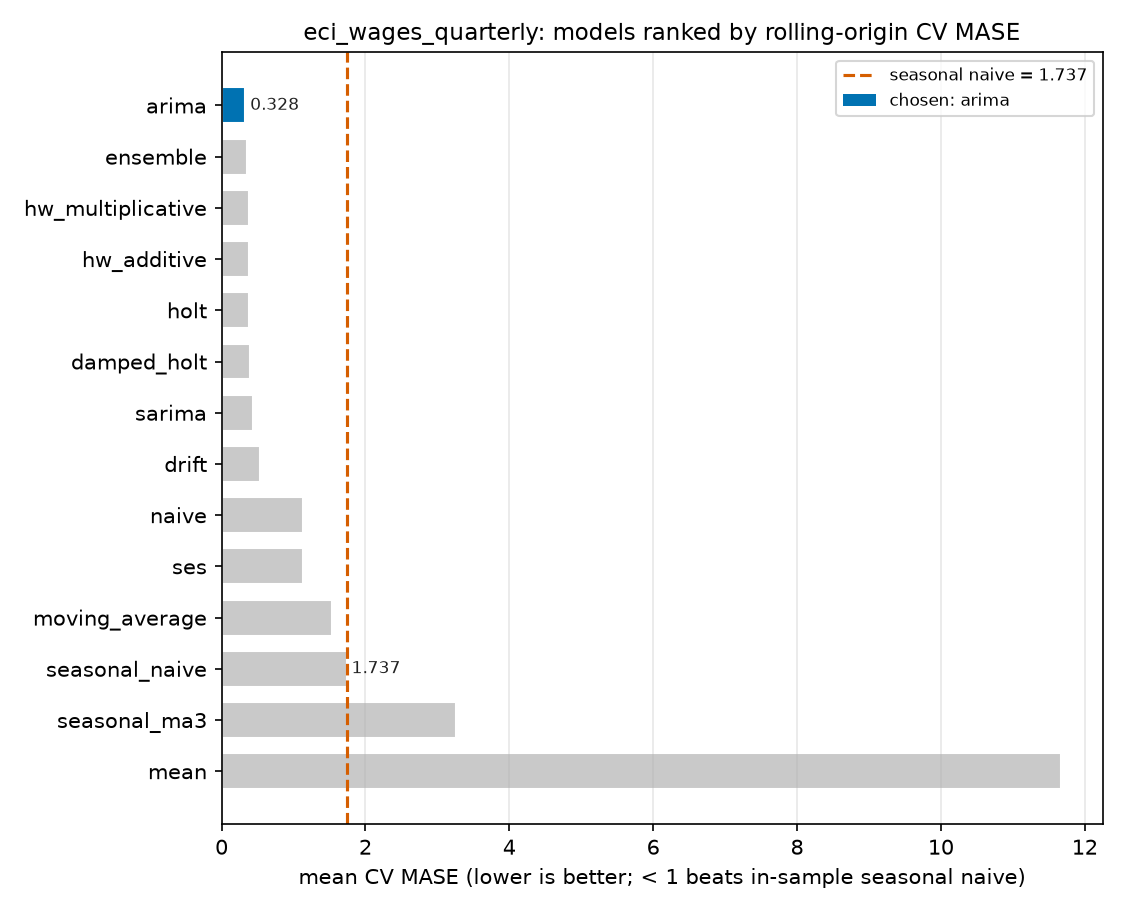

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,arima,arima,0.328,1.0,0.353
1,ensemble,ensemble,0.351,1.0,0.274
2,hw_multiplicative,smoothing,0.376,1.0,0.195
3,hw_additive,smoothing,0.379,1.0,0.190
4,holt,smoothing,0.386,1.0,0.197


**ppi_hosting_monthly**

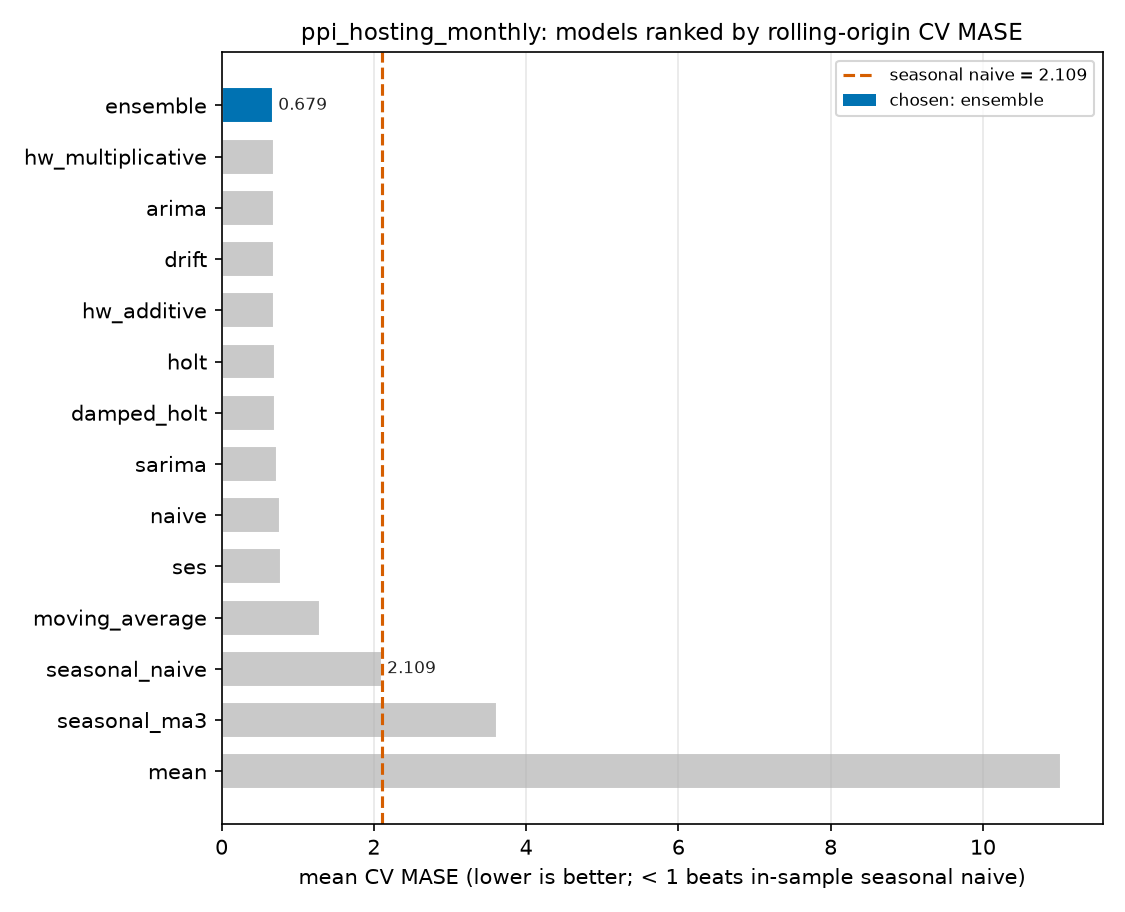

,model,family,cv_mase,share_beats_snaive,holdout_mase
0,ensemble,ensemble,0.679,0.921,2.376
1,hw_multiplicative,smoothing,0.686,0.895,2.444
2,arima,arima,0.689,0.921,2.309
3,drift,baseline,0.690,0.868,2.649
4,hw_additive,smoothing,0.694,0.895,2.462


In [21]:
with step("leaderboards"):
    lb = read_table("phase2", "leaderboard")
    ok = lb[lb["status"] == "ok"]
    for name in NAMES:
        display(Markdown(f"**{name}**"))
        show_img(f"outputs/phase2/figures/leaderboard_{name}.png", width=650)
        top = ok[ok["driver"] == name].sort_values("cv_mase").head(5)
        show_table(top, cols=["model", "family", "cv_mase", "share_beats_snaive", "holdout_mase"])

## C4. The chosen model per series
The rule: rank by mean CV MASE; a model is chosen only if it beats seasonal naive; ties within 1% go to
the simpler family. The `why` column shows the rule that was applied.

In [22]:
with step("chosen models"):
    ch = read_table("phase2", "chosen_models")
    show_table(ch, n=20, cols=["driver", "chosen_model", "family", "cv_mase", "holdout_mase",
                               "seasonal_naive_cv_mase", "beats_seasonal_naive", "why"])
    n_ens = int((ch["family"] == "ensemble").sum())
    n_base = int((ch["family"] == "baseline").sum())
    print(f"Won by the ensemble: {n_ens} | by a single model: {len(ch) - n_ens - n_base} | "
          f"by a baseline: {n_base} (of {len(ch)} series)")

,driver,chosen_model,family,cv_mase,holdout_mase,seasonal_naive_cv_mase,beats_seasonal_naive,why
0,burst_tokens_total_daily,ensemble,ensemble,0.424,1.003,0.529,True,"lowest mean CV MASE 0.424, below seasonal naive 0.529"
1,burst_tokens_api_daily,ensemble,ensemble,0.424,1.030,0.530,True,"lowest mean CV MASE 0.424, below seasonal naive 0.530"
2,burst_tokens_chat_daily,ensemble,ensemble,0.980,2.001,1.015,True,"lowest mean CV MASE 0.980, below seasonal naive 1.015"
3,burst_requests_hourly,ensemble,ensemble,0.755,1.834,0.822,True,"lowest mean CV MASE 0.755, below seasonal naive 0.822"
4,wildchat_conversations_daily,seasonal_ma3,baseline,1.430,2.451,1.507,True,"lowest mean CV MASE 1.430 (within 1% of the best, 1.423; simpler family preferred), be..."
5,eci_wages_quarterly,arima,arima,0.328,0.353,1.737,True,"lowest mean CV MASE 0.328, below seasonal naive 1.737"
6,ppi_hosting_monthly,ensemble,ensemble,0.679,2.376,2.109,True,"lowest mean CV MASE 0.679, below seasonal naive 2.109"


Won by the ensemble: 5 | by a single model: 1 | by a baseline: 1 (of 7 series)


## C5. Ensemble check: is the ensemble really better?
The ensemble averages the two models with the best CV MASE, so it was **chosen on the same CV folds**
it is scored on, and its CV score is optimistic. The **hold-out** was never used for choosing, so it is the
fair check: compare the ensemble's hold-out MASE with seasonal naive's on the same hold-out.

In [23]:
with step("ensemble check"):
    lb = read_table("phase2", "leaderboard").set_index(["driver", "model"])
    ch = read_table("phase2", "chosen_models").set_index("driver")
    rows = []
    for name in NAMES:
        if (name, "ensemble") not in lb.index:
            continue
        e, s = lb.loc[(name, "ensemble")], lb.loc[(name, "seasonal_naive")]
        rows.append({"driver": name, "chosen": ch.loc[name, "chosen_model"] if name in ch.index else "",
                     "ensemble of": e["reason"].replace("average of ", ""),
                     "ensemble CV MASE": e["cv_mase"], "ensemble hold-out MASE": e["holdout_mase"],
                     "seasonal naive hold-out MASE": s["holdout_mase"],
                     "ensemble better on hold-out": bool(e["holdout_mase"] < s["holdout_mase"])})
    show_table(pd.DataFrame(rows), n=20)

,driver,chosen,ensemble of,ensemble CV MASE,ensemble hold-out MASE,seasonal naive hold-out MASE,ensemble better on hold-out
0,burst_tokens_total_daily,ensemble,sarima and ridge,0.424,1.003,1.435,True
1,burst_tokens_api_daily,ensemble,sarima and ridge,0.424,1.030,1.443,True
2,burst_tokens_chat_daily,ensemble,seasonal_naive and ridge,0.980,2.001,2.002,True
3,burst_requests_hourly,ensemble,moving_average and ridge,0.755,1.834,2.413,True
4,wildchat_conversations_daily,seasonal_ma3,seasonal_ma3 and sarima,1.423,2.071,1.542,False
5,eci_wages_quarterly,arima,arima and hw_multiplicative,0.351,0.274,1.326,True
6,ppi_hosting_monthly,ensemble,hw_multiplicative and arima,0.679,2.376,1.742,False


## C6. Forecasts on the hold-out
History in black, the hold-out actual with dots, the chosen model in blue with its **80% and 95%
prediction intervals** (built from the model's own backtest errors), and seasonal naive dashed for comparison.

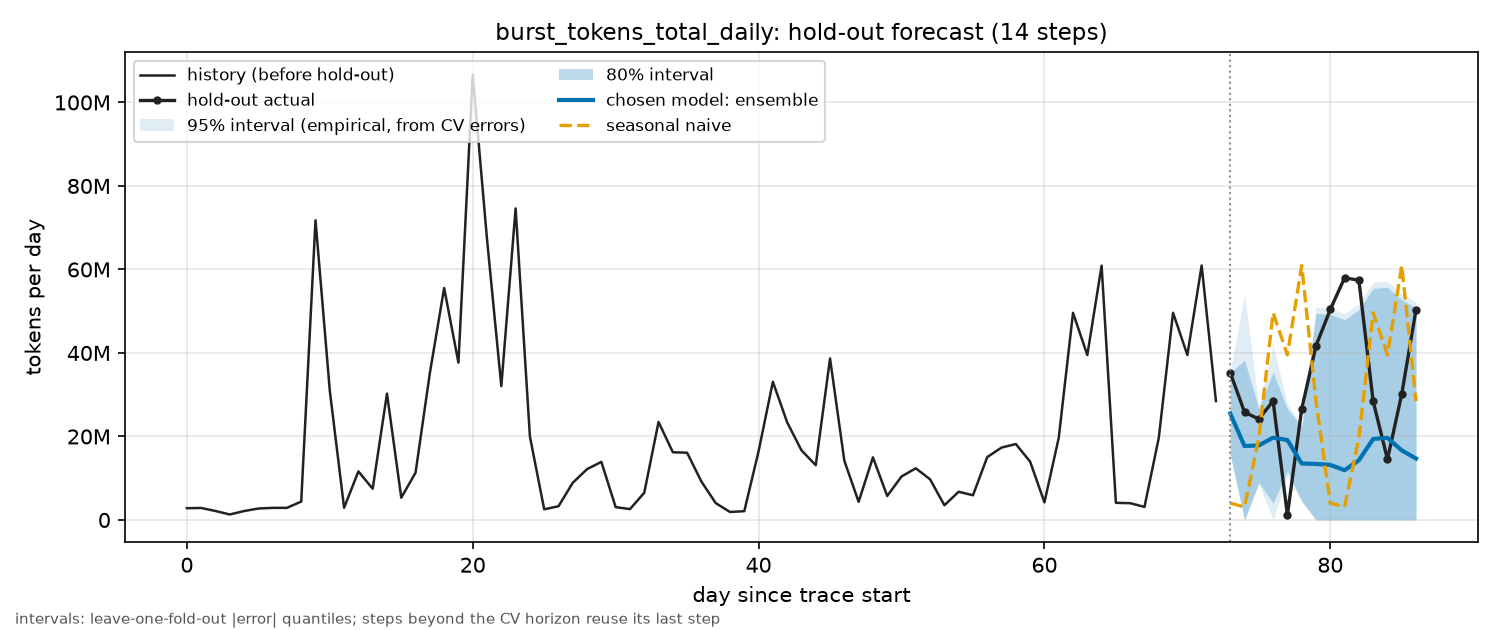

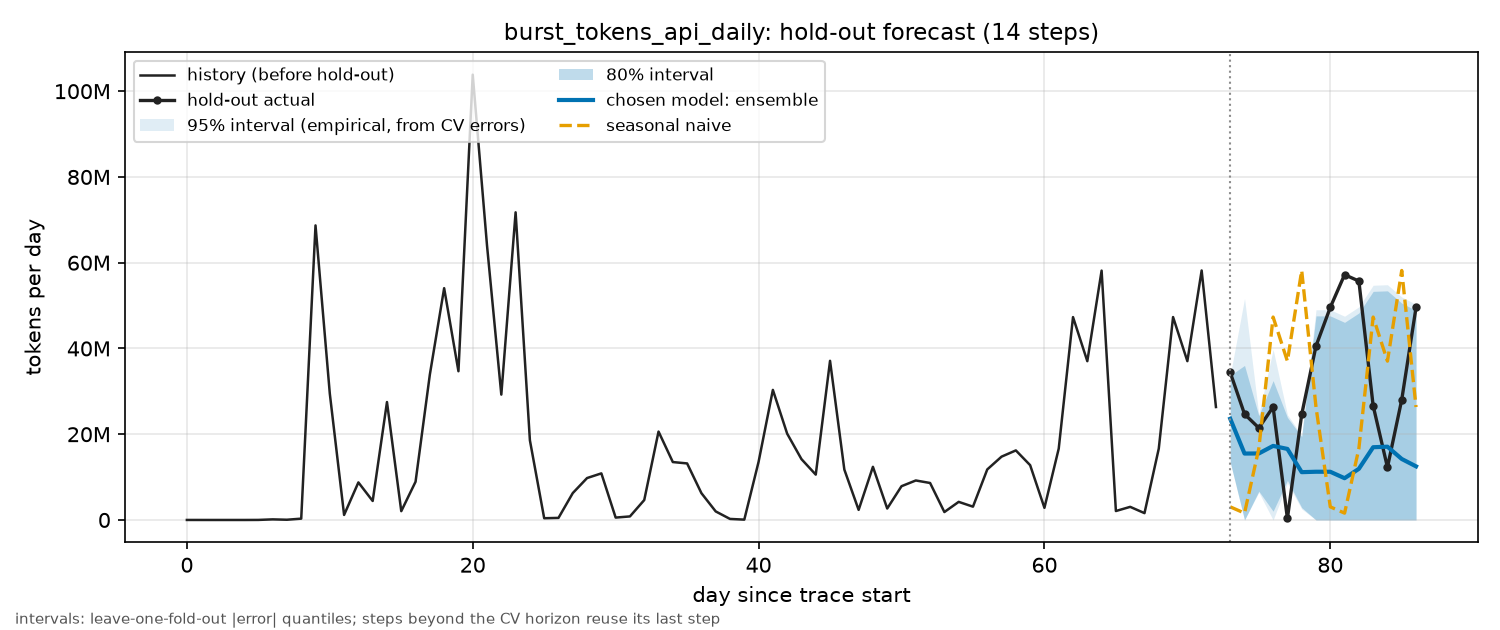

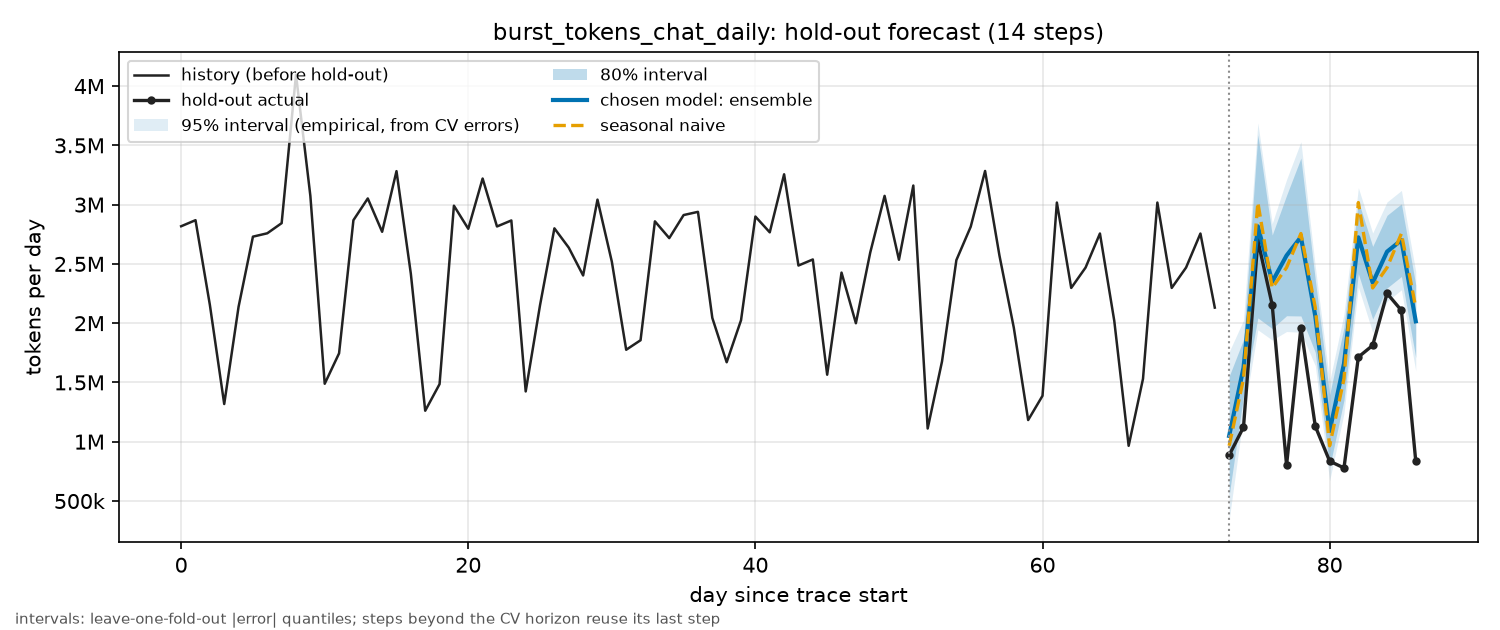

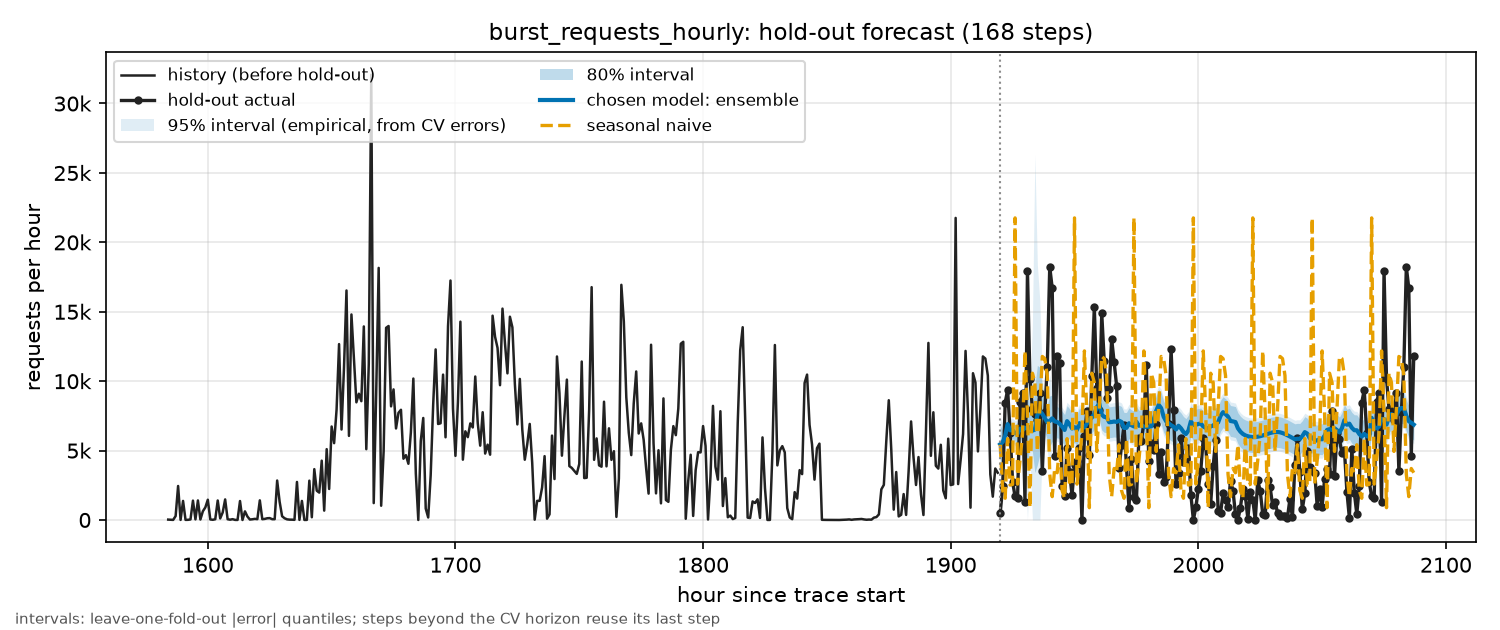

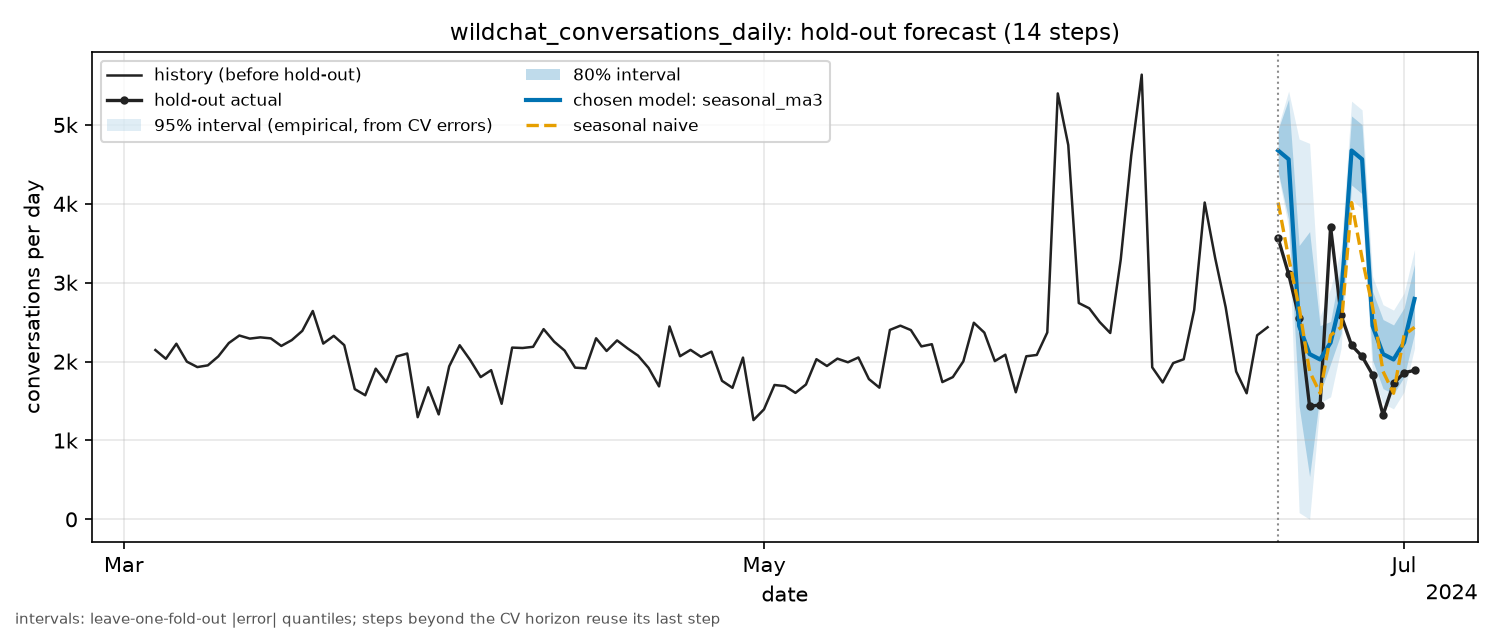

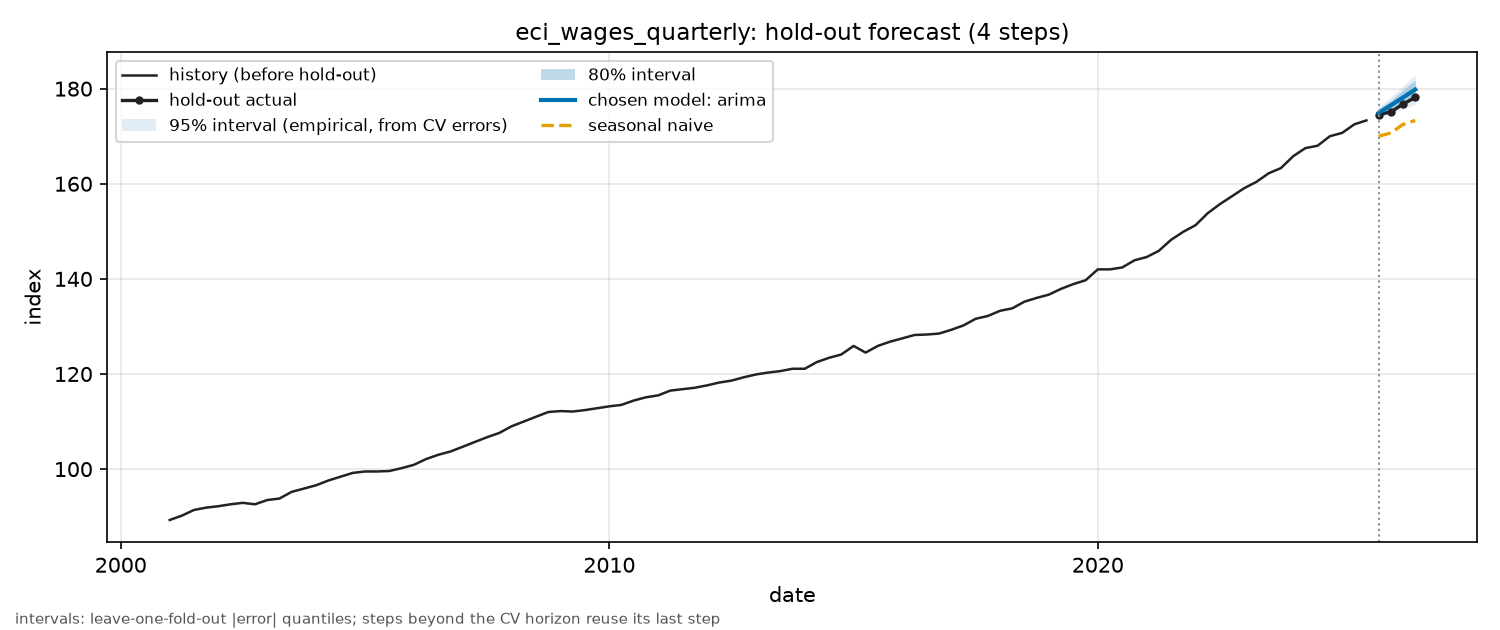

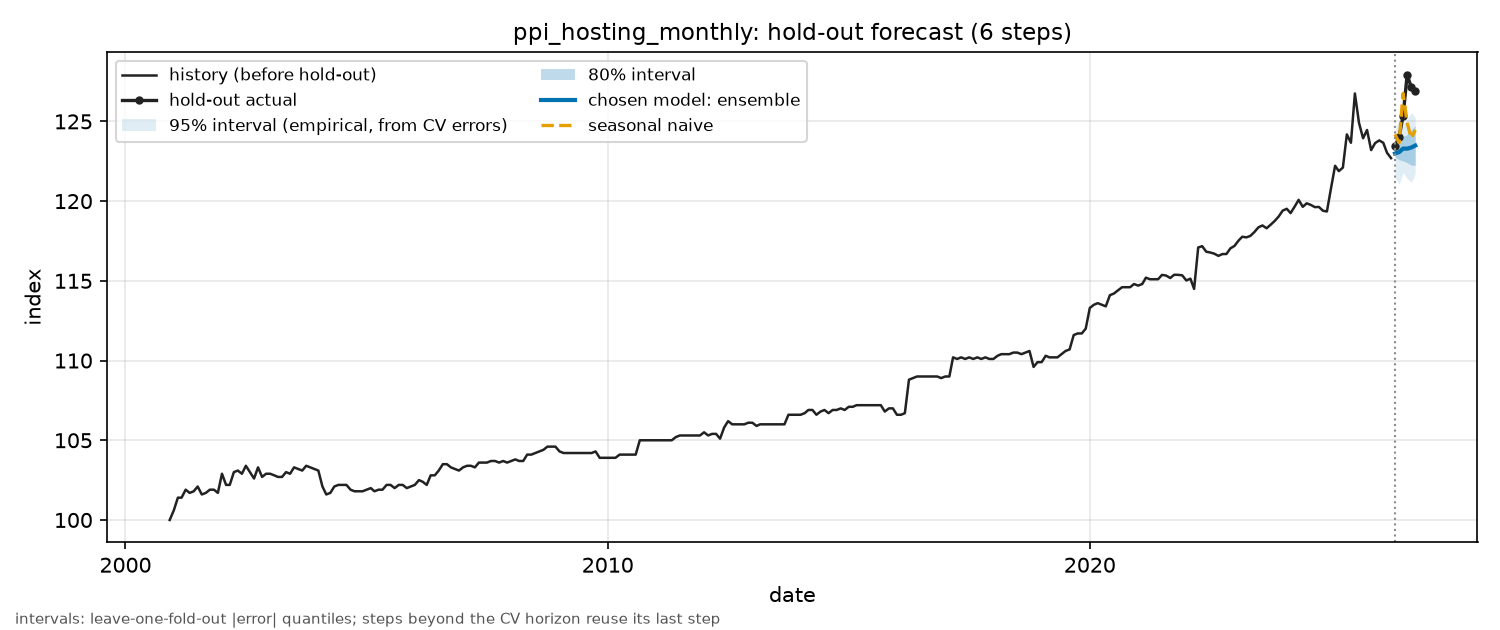

In [24]:
with step("forecasts"):
    for name in NAMES:
        show_img(f"outputs/phase2/figures/forecast_{name}.png", width=900)

## C7. Diagnostics: are the residuals just noise?
A good model leaves residuals (actual minus fitted) that look like **white noise**: no pattern left.
The **Ljung-Box test** checks this (p-value above 0.05 = looks like white noise). **Shapiro-Wilk** checks
normality. The **coverage** table checks the intervals: an 80% interval should contain about 80% of the
actual values; rows highlighted in orange fall short (below 60% for the 80% interval or below 85% for the 95% interval).

,driver,model,white_noise,ljung_box_p_lag10,ljung_box_p_lag14,ljung_box_p_lag48,ljung_box_p_lag8,ljung_box_p_lag24,shapiro_p,normal_residuals
0,burst_tokens_total_daily,ensemble,yes,0.781,0.923,NaN,NaN,NaN,0.000,no
1,burst_tokens_api_daily,ensemble,yes,0.787,0.929,NaN,NaN,NaN,0.000,no
2,burst_tokens_chat_daily,ensemble,no,0.014,0.009,NaN,NaN,NaN,0.567,yes
3,burst_requests_hourly,ensemble,no,0.000,NaN,0.0,NaN,NaN,0.000,no
4,wildchat_conversations_daily,seasonal_ma3,no,0.000,0.000,NaN,NaN,NaN,0.000,no
5,eci_wages_quarterly,arima,yes,0.316,NaN,NaN,0.24,NaN,0.020,no
6,ppi_hosting_monthly,ensemble,yes,0.088,NaN,NaN,NaN,0.72,0.000,no


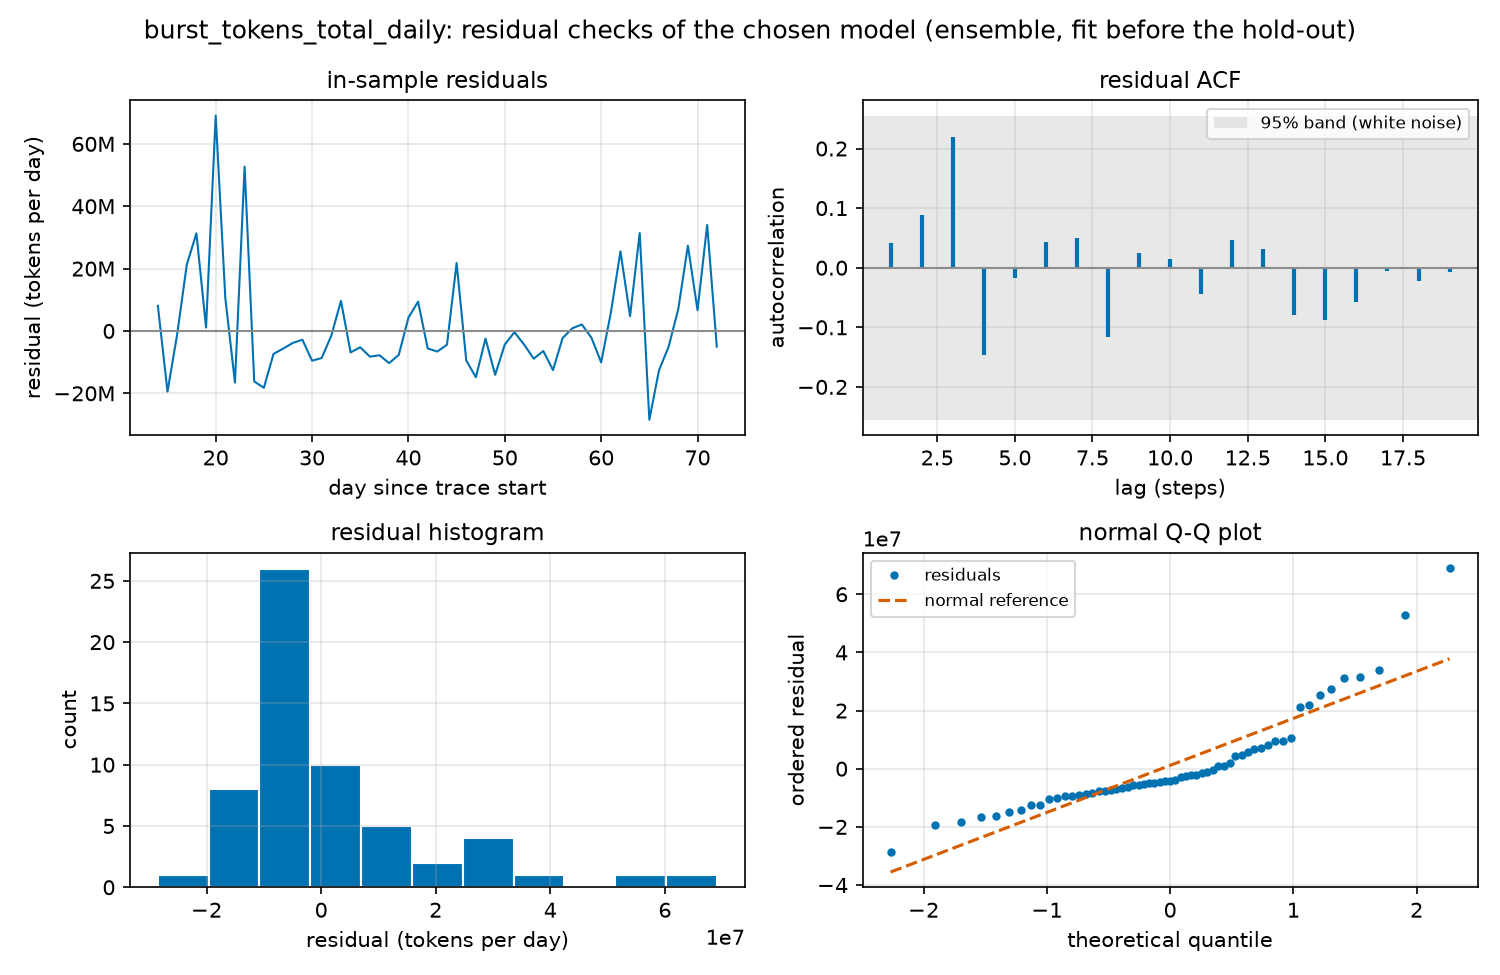

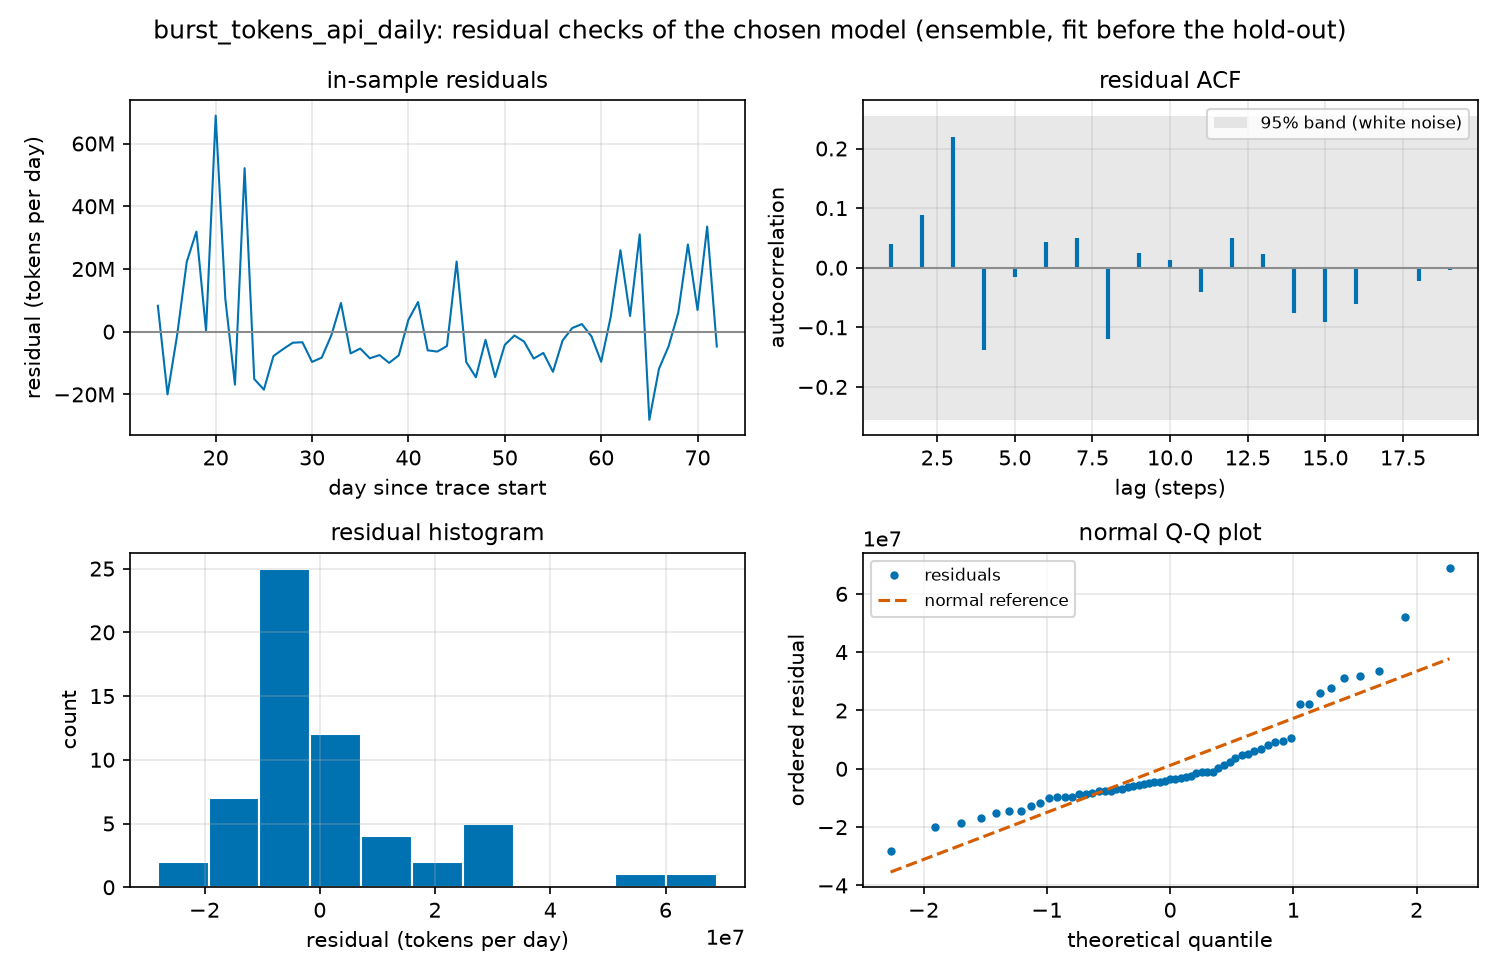

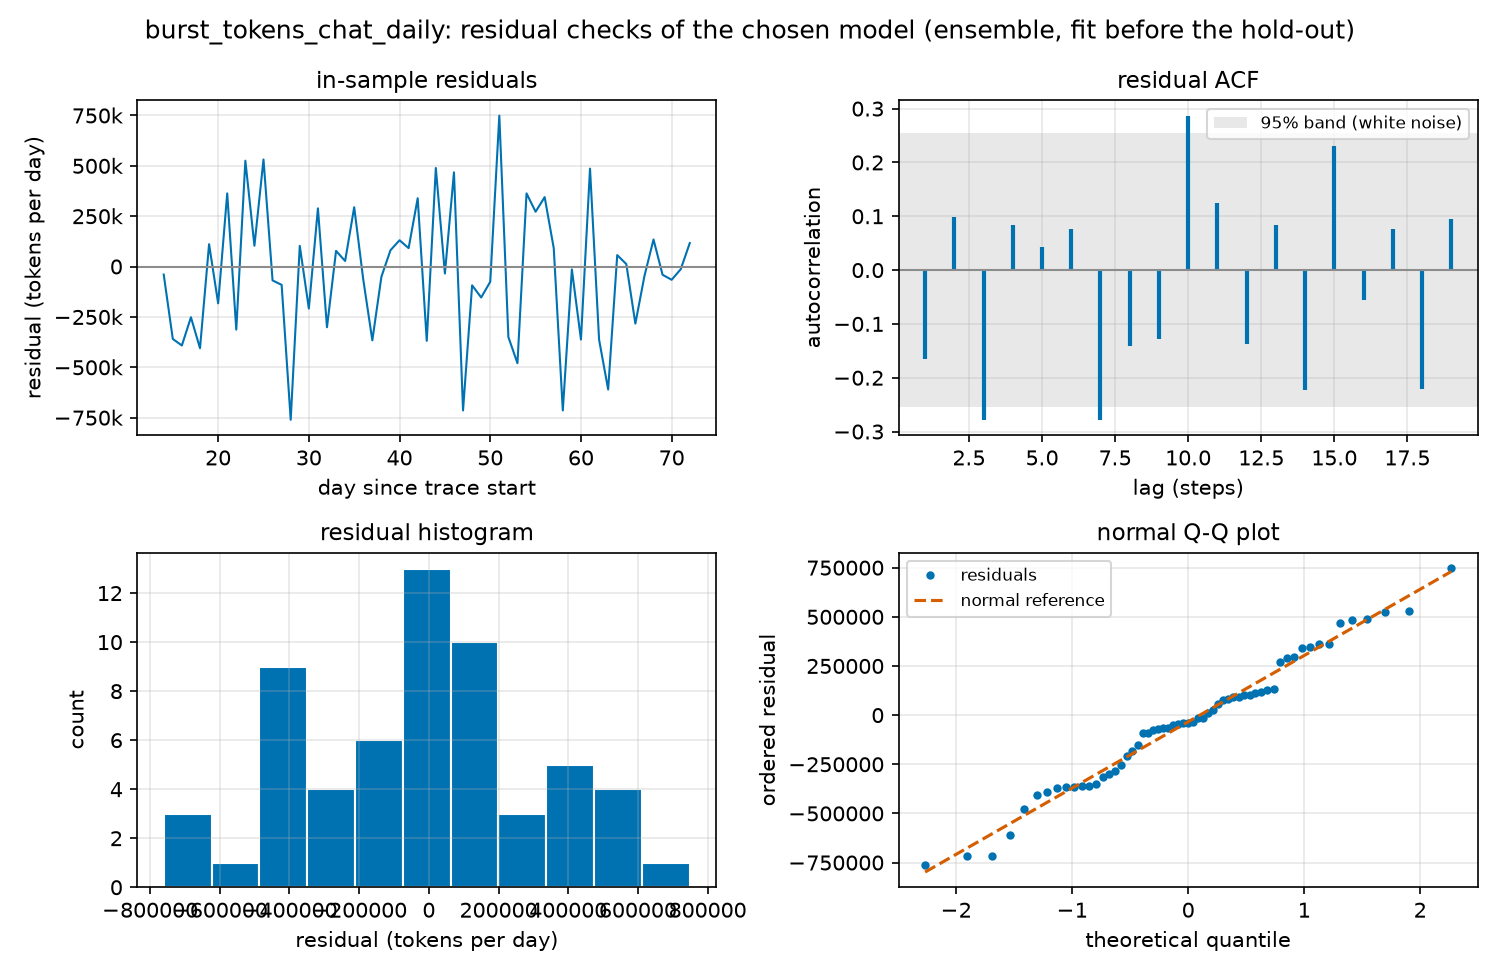

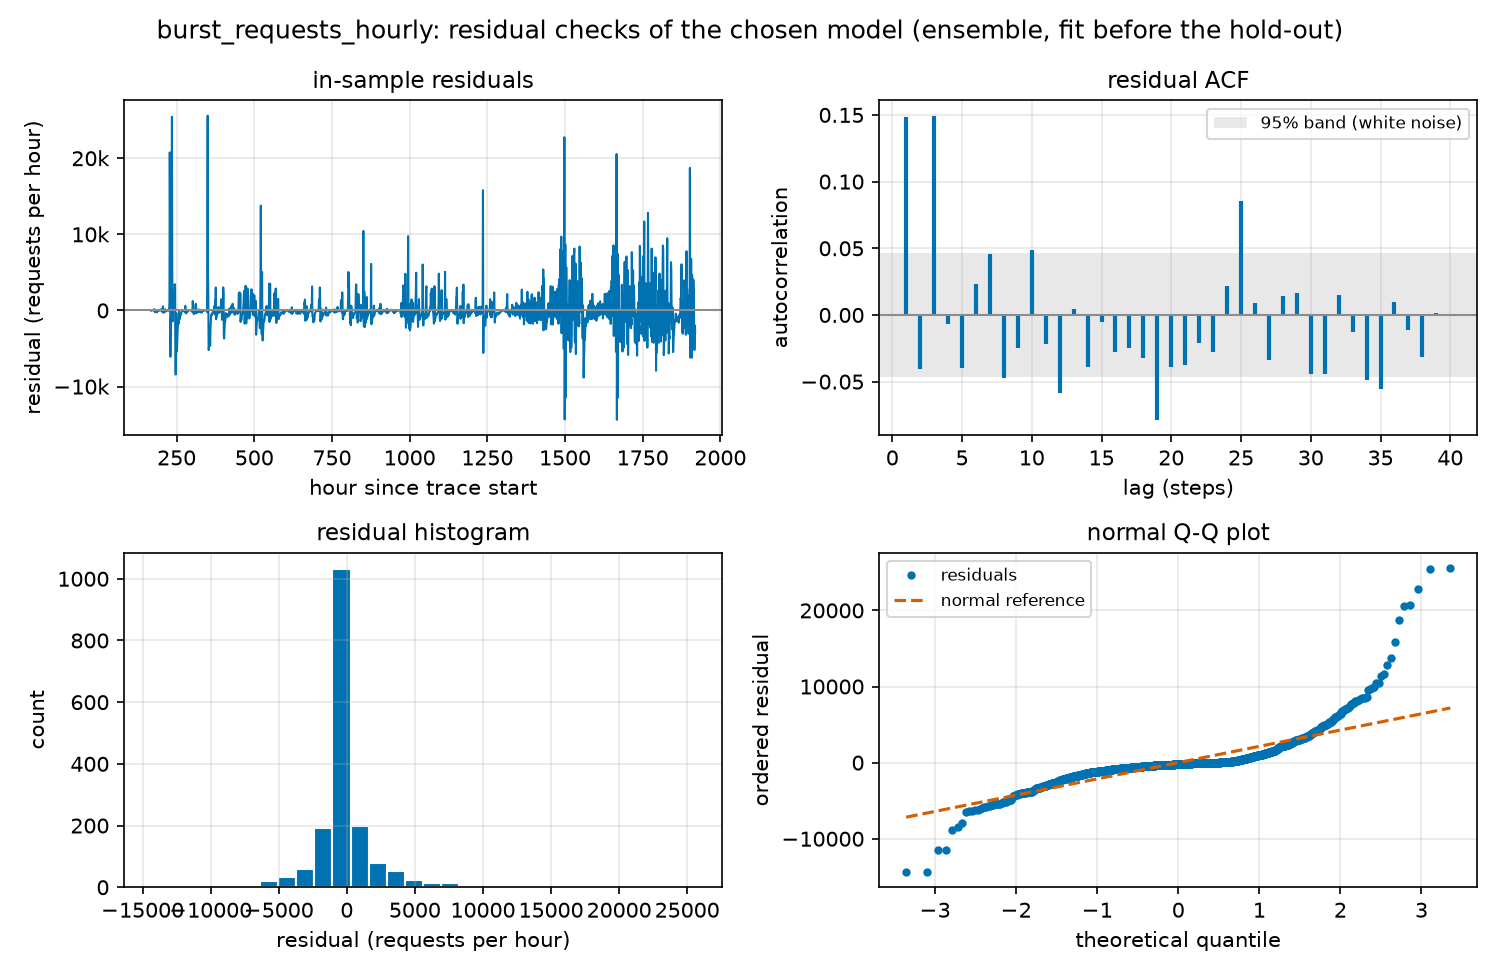

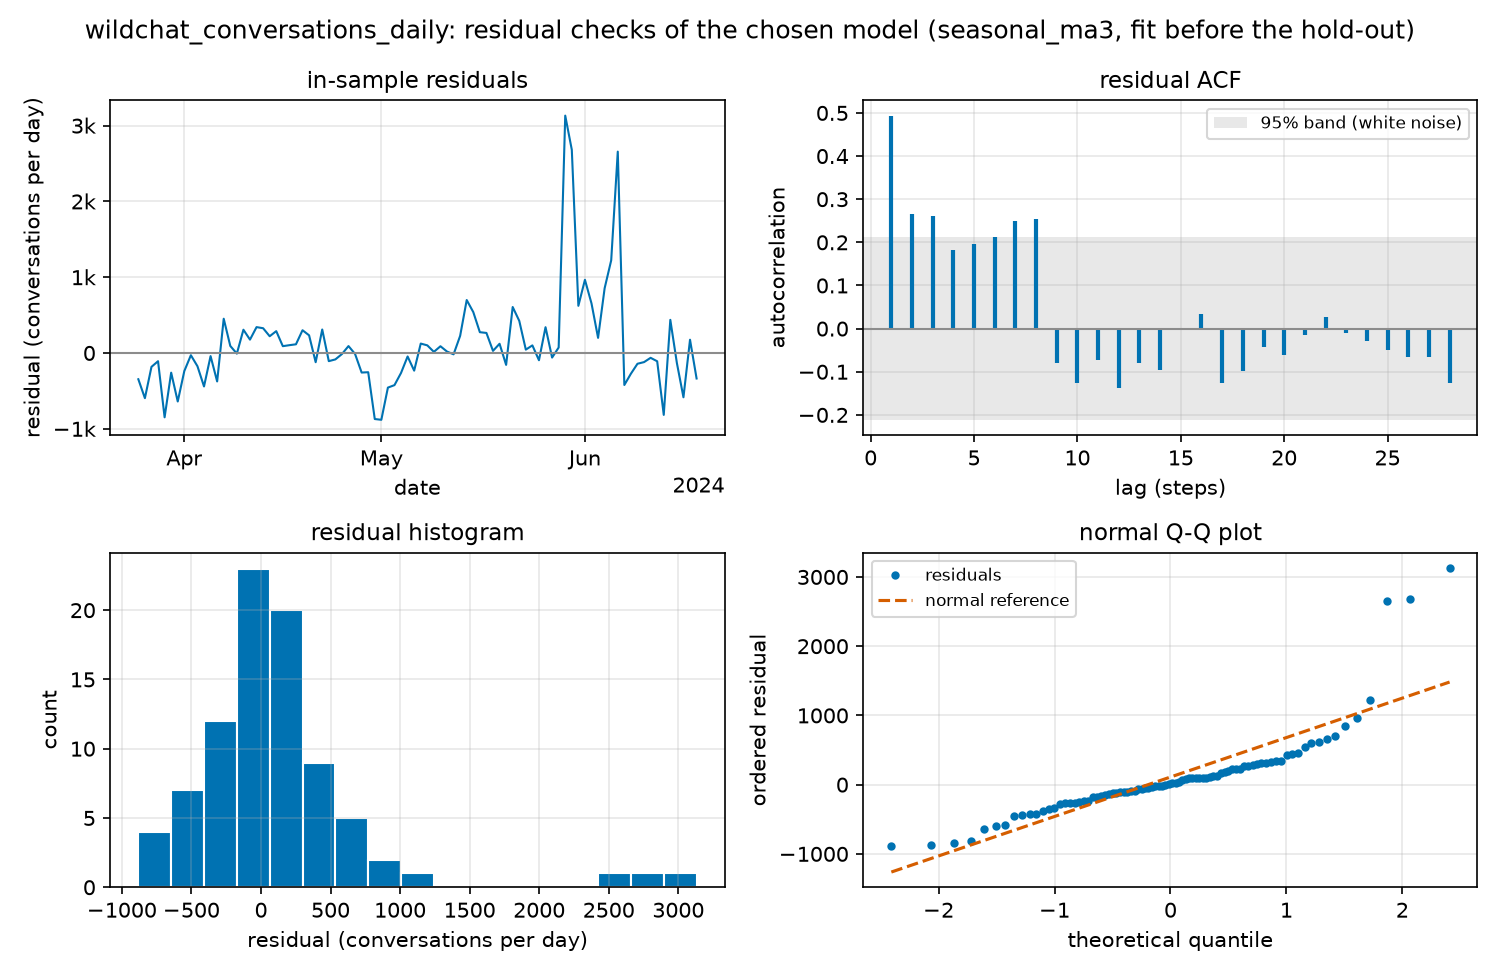

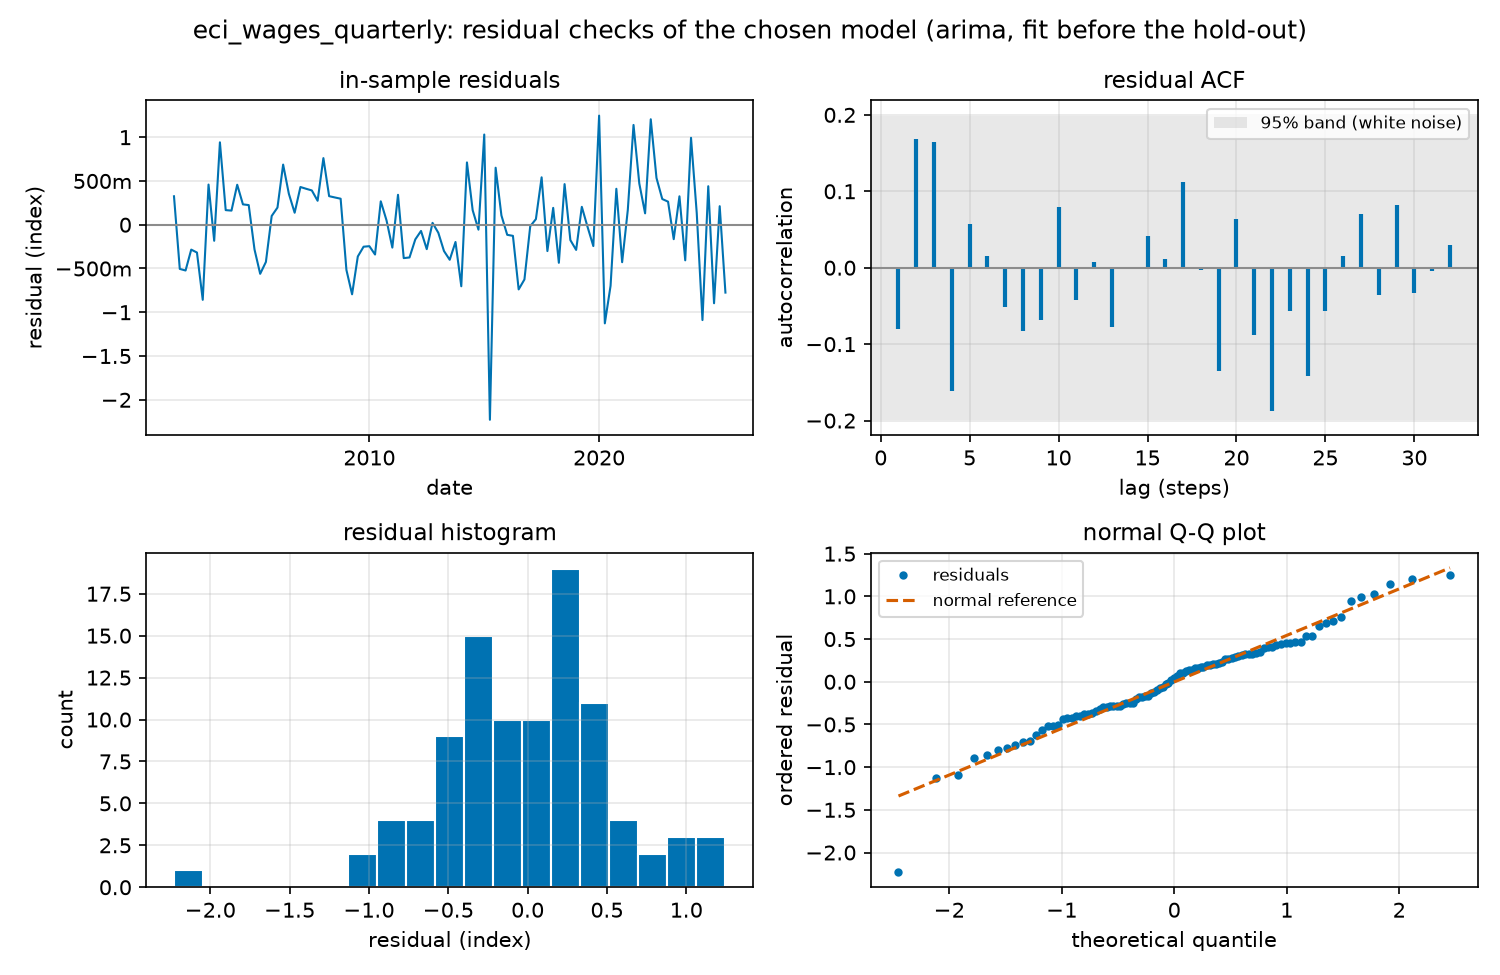

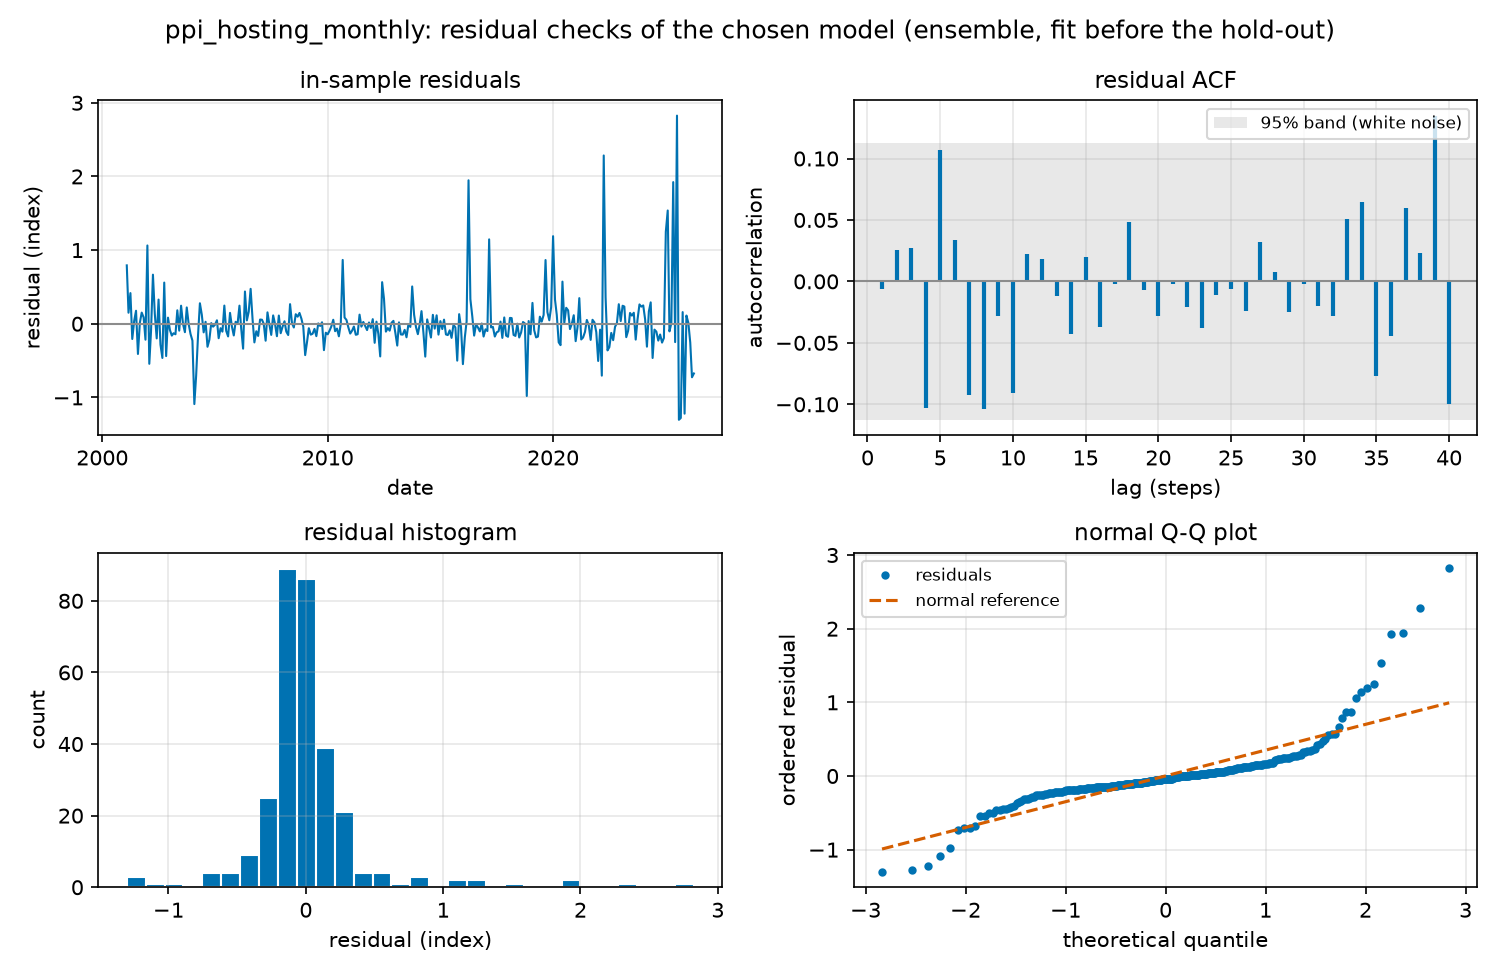

In [25]:
with step("residual diagnostics"):
    rd = read_table("phase2", "residual_diagnostics")
    lag_cols = [c for c in rd.columns if c.startswith("ljung_box_p_lag")]
    show_table(rd, n=20, cols=["driver", "model", "white_noise", *lag_cols, "shapiro_p", "normal_residuals"])
    for name in NAMES:
        show_img(f"outputs/phase2/figures/residuals_{name}.png", width=850)

In [26]:
with step("interval coverage"):
    cov = read_table("phase2", "interval_coverage")
    ch = read_table("phase2", "chosen_models")
    keep = set(zip(ch["driver"], ch["chosen_model"])) | {(d, "seasonal_naive") for d in ch["driver"]}
    sub = cov[[(d, m) in keep for d, m in zip(cov["driver"], cov["model"])]].copy()
    sub["flags"] = sub["flags"].fillna("")
    sub = sub[["driver", "model", "n_folds", "coverage_80", "coverage_95", "flags"]].round(3).reset_index(drop=True)
    print(f"{int(cov['flags'].fillna('').str.contains('coverage').sum())} of {len(cov)} model-series pairs have a coverage warning; "
          "chosen models and seasonal naive shown below.")
    try:
        display(sub.style.apply(lambda r: ["background-color: #FBD9C4" if "coverage" in r["flags"] else "" for _ in r], axis=1)
                .format(precision=3))
    except Exception:
        display(sub)

71 of 118 model-series pairs have a coverage warning; chosen models and seasonal naive shown below.


,driver,model,n_folds,coverage_80,coverage_95,flags
0,burst_tokens_total_daily,seasonal_naive,4,0.643,0.714,95% interval coverage 71.4% < 85%
1,burst_tokens_total_daily,ensemble,4,0.643,0.714,95% interval coverage 71.4% < 85%
2,burst_tokens_api_daily,seasonal_naive,4,0.643,0.750,95% interval coverage 75.0% < 85%
3,burst_tokens_api_daily,ensemble,4,0.643,0.679,95% interval coverage 67.9% < 85%
4,burst_tokens_chat_daily,seasonal_naive,4,0.750,0.750,95% interval coverage 75.0% < 85%
5,burst_tokens_chat_daily,ensemble,4,0.750,0.750,95% interval coverage 75.0% < 85%
6,burst_requests_hourly,seasonal_naive,8,0.729,0.859,
7,burst_requests_hourly,ensemble,8,0.719,0.849,95% interval coverage 84.9% < 85%
8,wildchat_conversations_daily,seasonal_naive,9,0.714,0.825,95% interval coverage 82.5% < 85%
9,wildchat_conversations_daily,seasonal_ma3,9,0.762,0.841,95% interval coverage 84.1% < 85%


## C8. Machine-learning insight
Tree models report **feature importance**: how much each input reduced the error. `lag_k` is the value
k steps earlier, `roll_mean` and `roll_std` summarise the last week (or day), `cycle_sin/cos` encode the
weekday or hour. For total tokens we also tried adding **requests** (lagged 14 days) as an extra input.

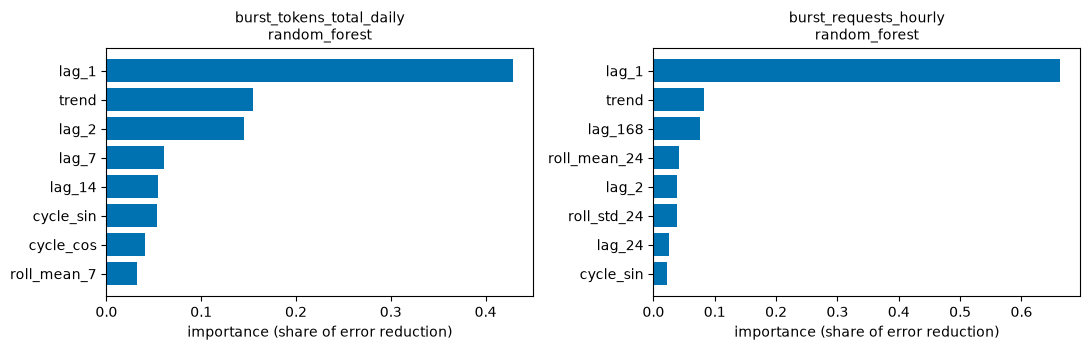

Mean CV MASE of the ML models on burst_tokens_total_daily, with and without requests:


variant,with requests,without,requests helped
base,,,
random_forest,0.842,0.809,False
ridge,0.505,0.496,False
xgboost,0.876,0.622,False


In [27]:
with step("feature importance"):
    import matplotlib.pyplot as plt
    fi = read_table("phase2", "feature_importance")
    pairs = [(d, "random_forest") for d in ("burst_tokens_total_daily", "burst_requests_hourly")
             if ((fi["driver"] == d) & (fi["model"] == "random_forest")).any()]
    if pairs:
        fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 3.6), squeeze=False)
        for ax, (d, m) in zip(axes[0], pairs):
            g = fi[(fi["driver"] == d) & (fi["model"] == m)].nlargest(8, "importance").iloc[::-1]
            ax.barh(g["feature"], g["importance"], color="#0072B2")
            ax.set_title(f"{d}\n{m}", fontsize=10)
            ax.set_xlabel("importance (share of error reduction)")
        plt.tight_layout()
        plt.show()
    lb = read_table("phase2", "leaderboard")
    t = lb[(lb["driver"] == "burst_tokens_total_daily") & (lb["family"] == "ml") & (lb["status"] == "ok")]
    if len(t):
        t = t.assign(base=t["model"].str.replace("_with_requests", "", regex=False),
                     variant=["with requests" if m.endswith("_with_requests") else "without" for m in t["model"]])
        comp = t.pivot(index="base", columns="variant", values="cv_mase").round(3)
        if {"with requests", "without"} <= set(comp.columns):
            comp["requests helped"] = comp["with requests"] < comp["without"]
        print("Mean CV MASE of the ML models on burst_tokens_total_daily, with and without requests:")
        display(comp)

**The recursive forecast** used by the machine-learning models: predict one step, append the prediction
to the history, rebuild the lag features, and repeat. This is how a one-step model produces a multi-step forecast.

In [28]:
with step("code: recursive forecast"):
    show_source("tsaf.models.ml", "recursive_forecast")

`tsaf.models.ml.recursive_forecast`
```python
def recursive_forecast(model, train: pd.Series, h: int, spec: FeatureSpec, grain: str,
                       extra: pd.Series | None = None) -> np.ndarray:
    """Predict one step, append it to the history, rebuild the features; repeat h times."""
    hist = pd.Series(np.asarray(train, dtype=float), index=train.index)
    labels = future_index(train.index, h, grain)
    preds = np.empty(h)
    for k in range(h):
        ext = pd.concat([hist, pd.Series([np.nan], index=labels[k:k + 1])])
        tail = ext.iloc[-spec.tail:]
        row = build_features(tail, spec, offset=len(ext) - len(tail), extra=extra).iloc[[-1]]
        if row.isna().any(axis=None):
            raise ValueError(f"step {k + 1}: feature row has NaN ({list(row.columns[row.isna().iloc[0]])})")
        preds[k] = float(np.asarray(model.predict(row)).reshape(-1)[0])
        ext.iloc[-1] = preds[k]
        hist = ext
    return preds
```

## C9. Prophet and LSTM (optional challengers)
Both are optional. Prophet needs the `prophet` package; the LSTM needs `torch` and the `--with-lstm` switch.

In [29]:
with step("prophet lstm"):
    lb = read_table("phase2", "leaderboard")
    for m in ("prophet", "lstm"):
        g = lb[lb["model"] == m]
        ran = g[g["status"] == "ok"]
        if len(ran):
            show_table(ran, cols=["driver", "model", "cv_mase", "holdout_mase"])
        else:
            reasons = sorted(set(g["reason"].fillna("")) - {""})
            why = next((r for r in reasons if "only for" not in r), reasons[0] if reasons else "not run")
            print(f"{m}: skipped (not installed or switched off): {why}")

prophet: skipped (not installed or switched off): skipped (not installed)
lstm: skipped (not installed or switched off): off by default (enable with --with-lstm)


## C10. Explore a series (optional, interactive)
Pick a series in the dropdown to see its leaderboard, forecast and residual figures together.
Nothing else in the notebook depends on this cell.

In [30]:
with step("explorer"):
    try:
        import ipywidgets as widgets
    except ImportError:
        widgets = None
        print("ipywidgets is not available; the figures above show the same content.")
    if widgets is not None and NAMES:
        box = widgets.Output()
        dd = widgets.Dropdown(options=NAMES, value=NAMES[0], description="series")
        def _show(change=None):
            box.clear_output()
            with box:
                for kind, w in (("leaderboard", 600), ("forecast", 850), ("residuals", 800)):
                    show_img(f"outputs/phase2/figures/{kind}_{dd.value}.png", width=w)
        dd.observe(_show, names="value")
        display(dd, box)
        _show()

Dropdown(description='series', options=('burst_tokens_total_daily', 'burst_tokens_api_daily', 'burst_tokens_ch…

Output()

# Part D: summary

The talking points and limitations below are taken directly from the two generated summary files,
so every number comes from the runs.

In [31]:
with step("summaries"):
    for path, label in (("outputs/phase1/PHASE1_SUMMARY.md", "Phase 1"), ("outputs/phase2/PHASE2_SUMMARY.md", "Phase 2")):
        for title in ("What to say in the review", "Limitations"):
            text = md_section(path, title)
            display(Markdown(f"### {label}: {title}\n\n" + (text or "_Section not found._")))

### Phase 1: What to say in the review

Phase 1 analysed 7 drivers with five benchmark forecasts and an expanding-window backtest. Variability differs a lot: burst_requests_hourly has a coefficient of variation of 1.70, while ppi_hosting_monthly has 0.06, so one model will not fit both. The rolling-std rule chose multiplicative for burst_tokens_total_daily, burst_tokens_api_daily, wildchat_conversations_daily, eci_wages_quarterly, ppi_hosting_monthly and additive for the rest. The strongest seasonality is in burst_tokens_chat_daily (STL seasonal strength 0.72). ADF and KPSS together give: burst_tokens_total_daily d=0, D=0, burst_tokens_api_daily d=0, D=0, burst_tokens_chat_daily d=0, D=1, burst_requests_hourly d=0, D=1, wildchat_conversations_daily d=0, D=1, eci_wages_quarterly d=1, D=1, ppi_hosting_monthly d=1, D=1. Best-baseline CV MASE is below 1 (better than in-sample seasonal naive) for 5 of 7 drivers; these MASE values are the bar Phase 2 must beat. For BurstGPT total tokens the least-squares trend is +0.89% of the mean per day. The day-77 outage check is FAIL: the residual screen does not separate a known outage from API bursts (see the finding below).

### Phase 1: Limitations

- BurstGPT has no calendar dates: time is days/hours since the trace started.
- The weekend (day_of_cycle 4-5) is inferred from lower volume, not known.
- The BurstGPT modelling window is only 87 days (12 weeks), so yearly effects cannot be seen.
- WildChat users are hashed IPs, an imperfect user ID; only 5 of 86 shards are downloaded.
- EDA decisions (d, D, decomposition) use the whole window including the hold-out.
- `burst_requests_hourly`: the 8 capped folds test positions 336-863 of the 1920 pre-hold-out points, not the most recent ones.
- Skipped drivers (reasons in section 1): `wildchat_conversations_weekly`, `wildchat_new_users_weekly`, `wildchat_returning_share_weekly`, `epoch_cheapest_price_monthly`.

### Phase 2: What to say in the review

Phase 2 scored 21 different models on 7 drivers, every model on the same expanding-window folds and hold-out as the Phase 1 baselines. A model beat seasonal naive on mean CV MASE for 7 of 7 drivers. The largest gain is on eci_wages_quarterly: arima reaches CV MASE 0.328 against 1.737 for seasonal naive (81% lower). For burst_tokens_total_daily the chosen model is ensemble (ensemble), CV MASE 0.424 and hold-out MASE 1.003. For burst_requests_hourly the chosen model is ensemble (ensemble), CV MASE 0.755 and hold-out MASE 1.834. Hold-out MASE is higher than CV MASE for 7 of 7 chosen models, so the final two weeks (or last periods) are harder than the backtest windows; the hold-out was never used for choosing. The chosen models come from these families: arima, baseline, ensemble; no single family wins everywhere. Empirical leave-one-fold-out intervals are too narrow for 71 of 118 model-driver pairs; with as few as 4 folds each interval rests on 3 errors per step. The day-77 outage check is FAIL (|robust z| 1.752 against 3.5). Hyper-parameters were chosen on the first training window only and kept fixed, so no fold ever saw its own test data.

### Phase 2: Limitations

- Short window: BurstGPT has 87 clean days (12 weeks); burst_tokens_total_daily, burst_tokens_api_daily, burst_tokens_chat_daily have fewer than 5 folds, so mean CV MASE rests on few windows.
- Hyper-parameters (ARIMA orders, moving-average window, Ridge alpha) are tuned on the first training window only; smoothing parameters are re-estimated in every fold.
- Intervals are empirical (leave-one-fold-out quantiles of absolute errors); with few folds the 95% quantile is close to the largest of a handful of errors and under-covers.
- The ensemble's two components are picked by the same CV MASE it is then scored on, so its CV score is optimistic; its hold-out score is the fair check.
- BurstGPT weekend (day_of_cycle 4 and 5) is inferred from lower volume, not known.
- Prophet would use an arbitrary start date (2000-01-03) as an index only.
- burst_requests_hourly: the 8 capped folds (Phase 1 settings) test positions 336-863 of the 1920 pre-hold-out hours, not the most recent weeks.
- All models forecast the raw scale (no log transform), and forecasts are clipped at 0.

In [32]:
with step("what we have"):
    def _count(folder, pattern="*"):
        p = Path(folder)
        return len(list(p.glob(pattern))) if p.exists() else 0
    rows = [
        {"phase": "1. Exploration and baselines", "built": "loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines, backtest",
         "outputs": f"outputs/phase1: {_count('outputs/phase1/tables')} tables, {_count('outputs/phase1/figures')} figures, handoff.json, PHASE1_SUMMARY.md"},
        {"phase": "2. Forecasting models", "built": "smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, model choice",
         "outputs": f"outputs/phase2: {_count('outputs/phase2/tables')} tables, {_count('outputs/phase2/figures')} figures, chosen_models.json, PHASE2_SUMMARY.md"},
    ]
    display(Markdown("### What we have so far"))
    display(pd.DataFrame(rows))

### What we have so far

,phase,built,outputs
0,1. Exploration and baselines,"loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines...","outputs/phase1: 10 tables, 30 figures, handoff.json, PHASE1_SUMMARY.md"
1,2. Forecasting models,"smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, m...","outputs/phase2: 11 tables, 28 figures, chosen_models.json, PHASE2_SUMMARY.md"


### Next steps
- **Phase 3**: standard forecast tables per series, with 200 simulated future paths built from the saved backtest errors.
- **Phase 4**: a Monte Carlo cost and value engine that turns those paths into cost and value distributions.
- **Phase 5**: an interactive dashboard.
- **Phase 6**: the final report.